In [ ]:
# from tqdm import tqdm
# from lerobot.datasets.lerobot_dataset import LeRobotDataset

# dataset = LeRobotDataset("TomasAnderegg/so101_pill_sorting")
# # print(dataset.meta)
# # print("--------")
# # print(dataset.meta.fps)
# dir(dataset.meta.episodes) # Pour voir la structure
# print(dataset.meta.episodes)

In [ ]:
import os, getpass
from huggingface_hub import login

token = getpass.getpass("Paste your HF token: ")
login(token=token)              # saves it for this machine, so later `!` commands find it
os.environ["HF_TOKEN"] = token

In [ ]:
from tqdm import tqdm
from lerobot.datasets.lerobot_dataset import LeRobotDataset

# dataset = LeRobotDataset("TomasAnderegg/so101_pill_sorting")
# dataset = LeRobotDataset("TomasAnderegg/so101_pill_sorting_test_trash") #test hypothesis:  --dataset.streaming_encoding=false instead of true
dataset = LeRobotDataset("TomasAnderegg/so101_pill_sorting_merged_v2")

# dir(dataset.meta) # Pour voir la structure
count = 0
frames_missing = 0
episode_id = []
for i in range(dataset.meta.total_episodes):
    episode = dataset.meta.episodes[i]
    
    from_tp_to_tp = episode['videos/observation.images.front/to_timestamp'] - episode['videos/observation.images.front/from_timestamp']
    video_frames_meta = round( from_tp_to_tp *dataset.meta.fps)
    
    if video_frames_meta != episode['length']:
        count = count + 1
        frames_missing =  frames_missing + abs(video_frames_meta - episode['length'])
        episode_id.append(episode['episode_index'])
        print("not match for episode:", episode['episode_index'], "with a difference of:",video_frames_meta - episode['length'], ",for the task:",episode['tasks']  )
if frames_missing != 0:
    print("total problematic videos", count, ", for an average of", frames_missing/count, " frames were missing")

Out of the 96 videos recorded, 28 videos have missing frames for an average of ~3 frames per recording. A copy of the dataset will be modify and used for the rest of the project.

In [ ]:
import os, sys
os.environ["PATH"] = os.path.join(os.path.dirname(sys.executable), "Scripts") + os.pathsep + os.environ["PATH"]

!hf auth whoami
!hf repos duplicate TomasAnderegg/so101_pill_sorting TomasAnderegg/so101_pill_sorting_copy --type dataset


In [ ]:
# print(type(episode_id))
print(episode_id)

In [ ]:
# # Saved Locally and not pushed !! 
# !lerobot-edit-dataset --repo_id TomasAnderegg/so101_pill_sorting --new_repo_id TomasAnderegg/so101_pill_sorting_v2 --operation.type delete_episodes --operation.episode_indices "[2, 8, 10, 13, 14, 16, 17, 21, 24, 28, 31, 36, 43, 47, 48, 56, 61, 68, 70, 72, 73, 77, 78, 79, 85, 89, 90, 94]"
# Saved Locally and not pushed !! 
import shutil
import pandas as pd
from pathlib import Path

base = Path.home() / ".cache/huggingface/lerobot/TomasAnderegg"
root = base / "so101_pill_sorting_merged"
meta_dir = root / "meta/episodes"

shutil.copytree(meta_dir, root / "meta/episodes_backup", dirs_exist_ok=True)      # backup
shutil.rmtree(base / "so101_pill_sorting_merged_delete_83", ignore_errors=True)   # leftover from the failed run

for p in sorted(meta_dir.glob("chunk-*/file-*.parquet")):
    chunk, file = int(p.parent.name.split("-")[1]), int(p.stem.split("-")[1])
    df = pd.read_parquet(p)
    wrong = ((df["meta/episodes/chunk_index"] != chunk) | (df["meta/episodes/file_index"] != file)).sum()
    print(f"{p.parent.name}/{p.name}: {len(df)} episodes, {wrong} pointing to the wrong file")
    if wrong:
        df["meta/episodes/chunk_index"] = chunk
        df["meta/episodes/file_index"] = file
        df.to_parquet(p, index=False)

In [ ]:
!lerobot-edit-dataset --repo_id TomasAnderegg/so101_pill_sorting_merged --new_repo_id TomasAnderegg/so101_pill_sorting_merged_delete_83 --operation.type delete_episodes --operation.episode_indices "[83]" --push_to_hub true

In [ ]:
ds =LeRobotDataset("TomasAnderegg/so101_pill_sorting_merged_delete_83",root=r"C:\Users\tjga9\.cache\huggingface\lerobot\TomasAnderegg\so101_pill_sorting_merged_delete_83" )
print("total ep:", ds.meta.total_episodes)
# print(dataset.meta.total_episodes - len(episode_id)) verification
ds.push_to_hub()

Because the tool kit provided my LeRobot doesn't allow me to add on top of an existing dataset. I'll need to create another dataset and then merged them. The script record_pills is adapted to record the relevant tasks. Once it will be done, the v2 and redo will me merged.

In [ ]:
!lerobot-edit-dataset --new_repo_id TomasAnderegg/so101_pill_sorting_merged_v2 --operation.type merge --operation.repo_ids "['TomasAnderegg/so101_pill_sorting_merged_delete_83', 'TomasAnderegg/so101_pill_sorting_yellow']"


In [ ]:
ds =LeRobotDataset("TomasAnderegg/so101_pill_sorting_merged_v2",root=r"C:\Users\tjga9\.cache\huggingface\lerobot\TomasAnderegg\so101_pill_sorting_merged_v2" )
print("total ep:", ds.meta.total_episodes)
# print(dataset.meta.total_episodes - len(episode_id)) verification
ds.push_to_hub()

## Fine-tuning deployment on the real hardware:


In [ ]:
!lerobot-rollout \
    --strategy.type=sentry \
    --strategy.upload_every_n_episodes=5 \
    --policy.path=TomasAnderegg/pill_sorting_post_trained_a100 \
    --policy.device=cpu \
    --robot.type=so101_follower \
    --robot.port=COM4 \
    --robot.cameras="{ front: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}}" \
    --dataset.repo_id=TomasAnderegg/eval_pill_sorting \
    --dataset.single_task="Put the red pill in the square compartment." \
    --inference.type=rtc \
    --duration=300

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", download_videos=False)
ep = np.array([int(e) for e in ds.hf_dataset["episode_index"]])
time = np.array([float(t) for t in ds.hf_dataset["timestamp"]])
gripper = np.stack(ds.hf_dataset["action"])[:, 5]

for e in range(300):
    plt.plot(time[ep == e], gripper[ep == e], alpha=0.2)   # one curve per episode

plt.xlabel("timestamp (s)")
plt.ylabel("gripper action")
plt.title("Gripper, all 300 episodes")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [0], download_videos = False)
# print(ds)
# print(len(ds.hf_dataset))
gripper_stack = []
time_stack = []
mean = 0
mean_episode = 0

episode_length = len(ds.hf_dataset)
total_lenght = 0
total_lenght += episode_length

for i in range(len(ds.hf_dataset)):
    gripper_stack.append(ds.hf_dataset[i]["action"][5])
    time_stack.append(ds.hf_dataset[i]["timestamp"])
    # print("gripper_stack:", gripper_stack)
    # print("timestamp stack:", time_stack)
gripper_sort = np.sort(gripper_stack)
# print(np.unique(gripper_sort))
# plt.plot(time_stack, gripper_stack)

t = np.array(time_stack)      # numpy arrays, so that t[g == v] works
g = np.array(gripper_stack)   # the curve, in time order (not sorted)

top2 = np.unique(g)      # the 2 largest different values

plt.plot(t, g)                # the curve
for v in top2:
    plt.scatter(t[g == v], g[g == v], color="red", zorder=3)   # red dots where the curve equals v
plt.show()

### Threshold calculation:
To establish the threshold to detect if the grab something and release it. I am going to first detect if there are 2 spikes. 
1. Approach n°1: if the value is above the mean of the max gripper values then, the robot is either grabbing or releasing. A boolean value will be added to detect if it is grabbing(grab = True) or releasing (grab = False).
2. Approach n°2: detecting a big variation of the value to detect the number of spike and the moment.

In [ ]:
## Approach 1: does not work because the max value can be located a the same surroundings and could not represent the 2 spikes (c.f plot)
# ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", download_videos=False)

# ep = np.array([int(e) for e in ds.hf_dataset["episode_index"]])
# gripper = np.stack(ds.hf_dataset["action"])[:, 5]

# # On cherche la valeur max et moyenne par episode
# for e in np.unique(ep):
#     g = gripper[ep == e]  
#     top2 = np.unique(g)[-2:]        # sorted from small to large, keep the last 2
#     print("two largest:", top2[1], top2[0])      
#     print("episode", e, "max:", g.max(), "mean:", g.mean())

We cannot just take the 2 highest value, because it can be missleading. I am going to compute the highest variation. I'll just do it for 1 episode and then generalize it to all of them.

In [ ]:
# Approach 2:

import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [2], download_videos = False)
# print(ds)
# print(len(ds.hf_dataset))
gripper_stack = []
time_stack = []
gripper_var = []
time_var = []

prev_val = 0
grab = False

for i in range(len(ds.hf_dataset)):
    gripper_stack.append(ds.hf_dataset[i]["action"][5])
    time_stack.append(ds.hf_dataset[i]["timestamp"])

for i in range(len(gripper_stack)):
    if (gripper_stack[i] - prev_val) > 10.0:

        print("timestamp:", time_stack[i])
        print("val:", gripper_stack[i])
        gripper_var.append(gripper_stack[i])
        time_var.append(time_stack[i])

        prev_val = gripper_stack[i]
        grab = not grab
        print("grab state:", grab)
    elif (gripper_stack[i] - prev_val) < 0:
        prev_val = gripper_stack[i]

# print(np.unique(gripper_sort))
plt.plot(time_stack, gripper_stack)
plt.scatter(time_var, gripper_var, color="red",zorder=3)
plt.show()




In [ ]:
## For all the episodes:
import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", download_videos=False)   # all episodes
ep = np.array([int(e) for e in ds.hf_dataset["episode_index"]])
time = np.array([float(t) for t in ds.hf_dataset["timestamp"]])
gripper = np.stack(ds.hf_dataset["action"])[:, 5]

counts = []   # number of detections in each episode

for e in np.unique(ep):
    gripper_stack = gripper[ep == e]     # this episode's curve
    time_stack = time[ep == e]

    gripper_var = []
    time_var = []
    prev_val = 0                         # reset for each episode
    grab = False

    for i in range(len(gripper_stack)):
        if (gripper_stack[i] - prev_val) > 10.0:
            gripper_var.append(gripper_stack[i])
            time_var.append(time_stack[i])
            prev_val = gripper_stack[i]
            grab = not grab
        elif (gripper_stack[i] - prev_val) < 0:
            prev_val = gripper_stack[i]

    counts.append(len(time_var))
#     plt.plot(time_stack, gripper_stack, alpha=0.2)                    # the episode's curve
#     plt.scatter(time_var, gripper_var, color="red", s=10, zorder=3)   # its detections

# plt.show()
print("detections per episode:", counts)

The approach 2 is not working because on the same slope, it detects 2 variation, and changing the threshold could lead to loose the other spike.
3. Approach n°3: detect only once a increasing slope, then the decreasing one, this is for the first spike. The same is applied for the other spike. I am expecting to have 4 values: 2 incresing and 2 decreasing.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", download_videos=False)   # all episodes
ep = np.array([int(e) for e in ds.hf_dataset["episode_index"]])
time = np.array([float(t) for t in ds.hf_dataset["timestamp"]])
gripper = np.stack(ds.hf_dataset["action"])[:, 5]

counts = []   # number of detections in each episode

for e in np.unique(ep): #unique filter the duplicate numbers
    gripper_stack = gripper[ep == e]     # this episode's curve
    time_stack = time[ep == e]

    gripper_var = []
    time_var = []
    prev_val = 0                         # reset for each episode
    grab = False
    is_open = False

    for i in range(len(gripper_stack)):
        if (gripper_stack[i] - prev_val) >= 9.5 and not is_open and time_stack[i] > 6.0:    # increasing slope: gripper opens
            gripper_var.append(gripper_stack[i])
            time_var.append(time_stack[i])
            prev_val = gripper_stack[i]
            grab = not grab
            is_open = True
        elif (gripper_stack[i] - prev_val) < 0 and time_stack[i] > 10:                       # decreasing slope
            if is_open:                                               # first drop after opening: closing starts
                gripper_var.append(gripper_stack[i])
                time_var.append(time_stack[i])
                is_open = False
            prev_val = gripper_stack[i]

    counts.append(len(time_var))
#     plt.plot(time_stack, gripper_stack, alpha=0.2)                    # the episode's curve
#     plt.scatter(time_var, gripper_var, color="red", s=10, zorder=3)   # its detections

# plt.show()
#Problematic episodes
for idx, ep in enumerate(counts):
    if ep != 4:
        print("episode:", idx)

print("detections per episode:", counts)

In [ ]:
# Approach 3:

import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [72], download_videos = False)
# print(ds)
# print(len(ds.hf_dataset))
gripper_stack = []
time_stack = []
gripper_var = []
time_var = []

prev_val = 0
prev_time = 0
grab = False
open = False
for i in range(len(ds.hf_dataset)):
    gripper_stack.append(float(ds.hf_dataset[i]["action"][5]))
    time_stack.append(float(ds.hf_dataset[i]["timestamp"]))

for i in range(len(gripper_stack)):
    ##increasing slope
    if (gripper_stack[i] - prev_val) >= 8.0 and (open == False) and time_stack[i] >= 6.0:# and (time_stack[i]-prev_time)>=2.5:

        print("timestamp:", time_stack[i])
        print("val:", gripper_stack[i])
        gripper_var.append(gripper_stack[i])
        time_var.append(time_stack[i])

        prev_val = gripper_stack[i]
        prev_time = time_stack[i]
        grab = not grab
        open = not open
        # print("grab state:", grab)

    elif (gripper_stack[i] - prev_val) < 0 and time_stack[i] > 10.0 and (time_stack[i]-prev_time)>=0.5: ##decreasing slope
        if open == True:
            gripper_var.append(gripper_stack[i])
            time_var.append(time_stack[i])
            prev_val = gripper_stack[i]
            
            prev_time = time_stack[i]
            print("timestamp:", time_stack[i])
            print("val:", gripper_stack[i])
            open = not open
        else:
            prev_val = gripper_stack[i]
            prev_val = 0

# ## Area calculation: what I'm looking for is a big area followed by a small area.
# area = []
# segments = []                  # (a, b) frame range of each area
# max_height_list = []
# time_max_height_list = []

# for i in range(0, len(gripper_var) - 1, 2):       # pairs: (0,1), (2,3), ...
#     a = int(round(time_var[i] * 30))              # first detection: seconds -> frame
#     b = int(round(time_var[i+1] * 30))            # second detection

#     k = a + int(np.argmax(gripper_stack[a:b+1]))  # frame where the gripper is widest open
#     max_height = gripper_stack[k]
#     max_height_list.append(max_height)
#     time_max_height_list.append(time_stack[k])    # time of that frame, for the blue dot

#     width = np.abs(time_var[i+1] - time_var[i])
#     area.append(max_height * width)
#     segments.append((a, b))                       # same index as its area

# print("area:", area)

# ## Keep only 4 points: the big area and the area right after it
# if len(area) >= 2:
#     best = int(np.argmax(area[:-1]))     # biggest area that still has a next one -> always 4 points
#     keep = [best, best + 1]

#     new_gripper_var = []
#     new_time_var = []
#     new_max_height = []
#     new_time_max = []
#     for j in keep:
#         # area j comes from detections 2*j and 2*j+1
#         new_gripper_var += [gripper_var[2*j], gripper_var[2*j + 1]]
#         new_time_var += [time_var[2*j], time_var[2*j + 1]]
#         new_max_height.append(max_height_list[j])
#         new_time_max.append(time_max_height_list[j])

#     gripper_var = new_gripper_var          # update: now only 4 points
#     time_var = new_time_var
#     max_height_list = new_max_height
#     time_max_height_list = new_time_max

print("gripper_var:", gripper_var)
print("time_var:", time_var)

## Plot
plt.plot(time_stack, gripper_stack)                                          # full curve
plt.scatter(time_var, gripper_var, color="red", zorder=3)                   # the 4 kept points
# plt.scatter(time_max_height_list, max_height_list, color="blue", zorder=3)  # top of the 2 kept openings
plt.show()

In [ ]:
# Approach 3:

from lerobot.datasets.lerobot_dataset import LeRobotDataset
from tqdm import tqdm

import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [113], download_videos = False)
# print(ds)
# print(len(ds.hf_dataset))
gripper_stack = []
time_stack = []
gripper_var = []
time_var = []

slope = 0
slope_stack = []
open = False
for i in range(len(ds.hf_dataset)):
    gripper_stack.append(float(ds.hf_dataset[i]["action"][5]))
    time_stack.append(float(ds.hf_dataset[i]["timestamp"]))

# print(gripper_stack)
for i in range(0, len(gripper_stack)-1, 2):
    ##increasing slope
    slope = (gripper_stack[i+1]-gripper_stack[i])//(time_stack[i+1]-time_stack[i])
    # print("slope:", slope)
    
    if np.abs(slope) > 28.0:

        slope_stack.append(slope)
        gripper_var.append(gripper_stack[i])
        time_var.append(time_stack[i])

print(slope_stack)
grip_var_2 = []
time_var_2 = []
up =False
time_rec = 0
for i in range(len(slope_stack)):

    if slope_stack[i] > 0 and (time_var[i]-time_rec) > 1.25 and up == False:# and (time_var[i+1]-time_var[i]) > 1.0: #uprising
        grip_var_2.append(gripper_var[i])
        time_var_2.append(time_var[i])
        up = True
        time_rec = 0
    elif slope_stack[i] < 0 and up == True:# and (time_var[i+1]-time_var[i]) > 1.0:
        grip_var_2.append(gripper_var[i])
        time_var_2.append(time_var[i])
        time_rec = time_var[i]
        up = False

grip_var_3 = []
time_var_3 = []
# grip_var_2.pop(0)
# time_var_2.pop(0)
# print(time_var_2)
for i in range(0, len(grip_var_2)-1):
    # print("time diff:", time_var_2[i+1] - time_var_2[i])
    if (time_var_2[i+1] - time_var_2[i]) > 2.0:
        grip_var_3.append(grip_var_2[i])
        grip_var_3.append(grip_var_2[i+1])
        time_var_3.append(time_var_2[i])
        time_var_3.append(time_var_2[i+1])

# grip_var_3 = grip_var_3[-2:]
# time_var_3 = time_var_3[-2:] 

## Plot
plt.plot(time_stack, gripper_stack)                                          # full curve
# plt.scatter(time_var, gripper_var, color="red", zorder=3) 
plt.scatter(time_var_2, grip_var_2, color="red", zorder=3)                   # the 4 kept points
# plt.scatter(time_max_height_list, max_height_list, color="blue", zorder=3)  # top of the 2 kept openings
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", download_videos=False)   # all episodes
ep = np.array([int(e) for e in ds.hf_dataset["episode_index"]])
time = np.array([float(t) for t in ds.hf_dataset["timestamp"]])
gripper = np.stack(ds.hf_dataset["action"])[:, 5]

counts = []   # number of detections in each episode

for e in np.unique(ep): #unique filter the duplicate numbers
    gripper_stack = gripper[ep == e]     # this episode's curve
    time_stack = time[ep == e]

    gripper_var = []
    time_var = []
    prev_val = 0                         # reset for each episode
    grab = False
    is_open = False

    for i in range(len(gripper_stack)):
        if (gripper_stack[i] - prev_val) >= 9.5 and not is_open and time_stack[i] > 6.0:    # increasing slope: gripper opens
            gripper_var.append(gripper_stack[i])
            time_var.append(time_stack[i])
            prev_val = gripper_stack[i]
            grab = not grab
            is_open = True
        elif (gripper_stack[i] - prev_val) < 0 and time_stack[i] > 10:                       # decreasing slope
            if is_open:                                               # first drop after opening: closing starts
                gripper_var.append(gripper_stack[i])
                time_var.append(time_stack[i])
                is_open = False
            prev_val = gripper_stack[i]

    counts.append(len(time_var))
#     plt.plot(time_stack, gripper_stack, alpha=0.2)                    # the episode's curve
#     plt.scatter(time_var, gripper_var, color="red", s=10, zorder=3)   # its detections

# plt.show()
#Problematic episodes
count_ep = 0
list_problematic = []
for idx, ep in enumerate(counts):
    if ep != 4:
        # print("episode:", idx)
        list_problematic.append(idx)
        count_ep +=1 

print("detections per episode:", counts)
print("count of problematic episode:", list_problematic)

In [ ]:
# # Approach 3:

# import matplotlib.pyplot as plt
# import numpy as np
# print(list_problematic)
# for idx, ep in enumerate(list_problematic):
#     print("episode:", ep)
#     ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [ep], download_videos = False)
#     # print(ds)
#     # print(len(ds.hf_dataset))
#     gripper_stack = []
#     time_stack = []
#     gripper_var = []
#     time_var = []

#     prev_val = 0
#     grab = False
#     open = False
#     for i in range(len(ds.hf_dataset)):
#         gripper_stack.append(float(ds.hf_dataset[i]["action"][5]))
#         time_stack.append(float(ds.hf_dataset[i]["timestamp"]))

#     for i in range(len(gripper_stack)):
#         ##increasing slope
#         if (gripper_stack[i] - prev_val) >= 9.5 and (open == False) and time_stack[i] >= 6.0:

#             print("timestamp:", time_stack[i])
#             print("val:", gripper_stack[i])
#             gripper_var.append(gripper_stack[i])
#             time_var.append(time_stack[i])

#             prev_val = gripper_stack[i]
#             grab = not grab
#             open = not open
#             # print("grab state:", grab)

#         elif (gripper_stack[i] - prev_val) < 0 and time_stack[i] > 10.0: ##decreasing slope
#             if open == True:
#                 gripper_var.append(gripper_stack[i])
#                 time_var.append(time_stack[i])
#                 prev_val = gripper_stack[i]
#                 open = not open
#             else:
#                 prev_val = gripper_stack[i]

#     ## Area calculation: what I'm looking for is a big area followed by a small area.
#     area = []
#     segments = []                  # (a, b) frame range of each area
#     max_height_list = []
#     time_max_height_list = []

#     for i in range(0, len(gripper_var) - 1, 2):       # pairs: (0,1), (2,3), ...
#         a = int(round(time_var[i] * 30))              # first detection: seconds -> frame
#         b = int(round(time_var[i+1] * 30))            # second detection

#         k = a + int(np.argmax(gripper_stack[a:b+1]))  # frame where the gripper is widest open
#         max_height = gripper_stack[k]
#         max_height_list.append(max_height)
#         time_max_height_list.append(time_stack[k])    # time of that frame, for the blue dot

#         width = np.abs(time_var[i+1] - time_var[i])
#         area.append(max_height * width)
#         segments.append((a, b))                       # same index as its area

#     print("area:", area)

#     ## Keep only 4 points: the big area and the area right after it
#     if len(area) >= 2:
#         best = int(np.argmax(area[:-1]))     # biggest area that still has a next one -> always 4 points
#         keep = [best, best + 1]

#         new_gripper_var = []
#         new_time_var = []
#         new_max_height = []
#         new_time_max = []
#         for j in keep:
#             # area j comes from detections 2*j and 2*j+1
#             new_gripper_var += [gripper_var[2*j], gripper_var[2*j + 1]]
#             new_time_var += [time_var[2*j], time_var[2*j + 1]]
#             new_max_height.append(max_height_list[j])
#             new_time_max.append(time_max_height_list[j])

#         gripper_var = new_gripper_var          # update: now only 4 points
#         time_var = new_time_var
#         max_height_list = new_max_height
#         time_max_height_list = new_time_max

#     print("gripper_var:", gripper_var)
#     print("time_var:", time_var)

#     ## Plot
#     plt.plot(time_stack, gripper_stack)                                          # full curve
#     plt.scatter(time_var, gripper_var, color="red", zorder=3)                   # the 4 kept points
#     plt.scatter(time_max_height_list, max_height_list, color="blue", zorder=3)  # top of the 2 kept openings
#     plt.show()

In [ ]:
'''
Fonctions that allowed me to detect when the gripper is closed or open by analyzing the spikes in the gripper's value. 
The idea is to detect when the gripper opens -> big positive slop and when the gripper close -> big negative slope. 
To detect if the gripper is grabbing something and wants to drop it inside the compartement
a decreasing slope is followed by an increasing slope but not close in time ((time - prev_time) > 1.25 condition). 
'''
def slope_calculation(time_val, gripper_val):
    slope = 0
    gripper_list_val = []
    time_list_var = []
    slope_list = []

    for i in range(0, len(gripper_val)-1, 2):
    
        slope = (gripper_val[i+1]-gripper_val[i])//(time_val[i+1]-time_val[i])
        # print("slope:", slope)
        
        
        if np.abs(slope) > 28.0:

            slope_list.append(slope)
            gripper_list_val.append(gripper_stack[i])
            time_list_var.append(time_stack[i])

    return time_list_var, gripper_list_val, slope_list

def filter_slopes(time_list_var, gripper_list_val, slope_list):
    grip_var_filter = []
    time_var_filter = []
    time_decreasing = 0
    up =False
    
    for i in range(len(slope_list)):
        if slope_list[i] > 0 and up == False and (time_list_var[i] - time_decreasing) > 1.25: #uprising
            grip_var_filter.append(gripper_list_val[i])
            time_var_filter.append(time_list_var[i])
            time_decreasing = 0
            up = True
        elif slope_list[i] < 0 and up == True:
            grip_var_filter.append(gripper_list_val[i])
            time_var_filter.append(time_list_var[i])
            time_decreasing = time_list_var[i]
            up = False


    gripper = []
    time = []

    for i in range(0, len(grip_var_filter)-1):
        # print("time diff:", time_var_filter[i+1] - time_var_filter[i])
        if (time_var_filter[i+1] - time_var_filter[i]) > 2.0:
            gripper.append(grip_var_filter[i])
            gripper.append(grip_var_filter[i+1])
            time.append(time_var_filter[i])
            time.append(time_var_filter[i+1])

    # gripper = gripper[-2:]
    # time = time[-2:]

    # return  time, gripper
    return time_var_filter, grip_var_filter
def valley(time, gripper):
    pass

In [ ]:
# # Approach 3:

# from lerobot.datasets.lerobot_dataset import LeRobotDataset
# from tqdm import tqdm

# import matplotlib.pyplot as plt
# import numpy as np

# for idx, ep in enumerate(list_problematic):
#     ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [ep], download_videos = False)
#     print("episode:", ep)

#     gripper_stack = []
#     time_stack = []


#     for i in range(len(ds.hf_dataset)):
#         gripper_stack.append(float(ds.hf_dataset[i]["action"][5]))
#         time_stack.append(float(ds.hf_dataset[i]["timestamp"]))


#     time, gripper, slope = slope_calculation(time_stack, gripper_stack)
#     print("longeur temps:", len(time))
#     time , gripper = filter_slopes(time, gripper, slope)


#     ## Plot
#     # plt.plot(time_stack, gripper_stack)                                          # full curve
#     # # plt.scatter(time_var, gripper_var, color="red", zorder=3) 
#     # plt.scatter(time, gripper, color="red", zorder=3)                   # the 4 kept points
#     # # plt.scatter(time_max_height_list, max_height_list, color="blue", zorder=3)  # top of the 2 kept openings
#     # plt.show()

## Check now if the policy understand images and text !

In [ ]:
ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes = [0], download_videos = True)
# print(ds.hf_dataset)
# print(ds.hf_dataset["action"])
# print(ds.hf_dataset["observation.state"])
print(ds[0].keys())
timestamp = []
print("timestamp:", ds[760]["timestamp"])
for i in range(idx, idx + 50,1):
    timestamp.append(ds[i]["timestamp"])
print("list timestamps:", timestamp)
# print(ds[0]["task"])
# print(ds[0]["observation.images.front"])
# print(ds[0]["action"])


          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:01<00:00, 421.04it/s]


Reducing the number of VLM layers to 16 ...
reference                  | Put the yellow pill in the cross compartment.   (0 word changed)
colour yellow to red       | Put the red pill in the cross compartment.   (1 word changed)
compartment cross to circle | Put the yellow pill in the circle compartment.   (1 word changed)
verb Put to Place          | Place the yellow pill in the cross compartment.   (1 word changed)

reference, seed 0 repeated: max |Δ| = 0.00e+00

max-over-time |Δ| between two curves, mean ± std over pairs
joint          |       noise (seed pairs) |     colour yellow to red | compartment cross to circle |        verb Put to Place
shoulder_pan   |             4.25 ±  1.08 |             1.27 ±  0.23 |             1.81 ±  0.19 |             0.65 ±  0.10
shoulder_lift  |             6.59 ±  1.96 |            11.91 ±  3.24 |             1.43 ±  0.87 |             4.70 ±  1.37
elbow_flex     |             8.35 ±  2.23 |             6.97 ±  2.29 |             2.92 ±  0.94 | 

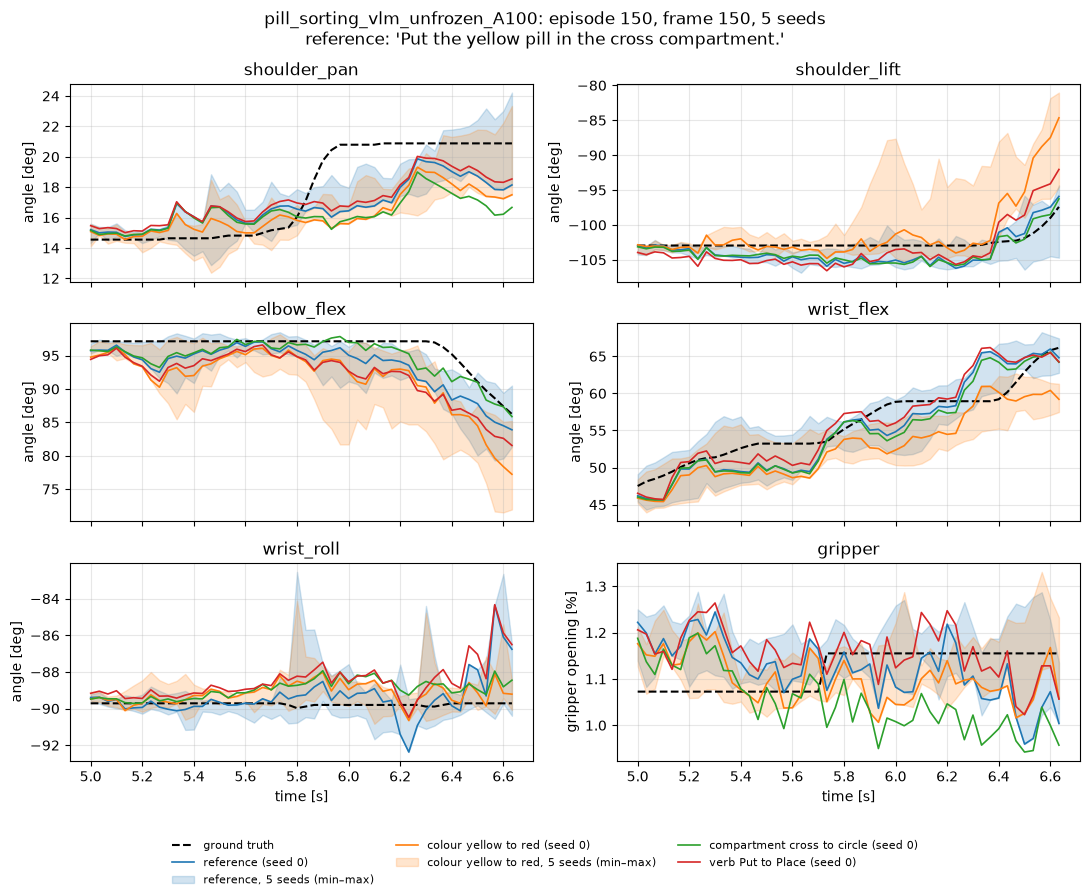

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from lerobot.datasets import LeRobotDataset
from lerobot.configs import PreTrainedConfig
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.policies.factory import make_pre_post_processors

# ---------------- config ----------------
EPISODE = 150
idx_colour = 150
H = 50                      #Prediction horizon of the VLA model (chunk length)
SEEDS = [0, 1, 2, 3, 4]
joint_names = ["shoulder_pan", "shoulder_lift", "elbow_flex",
               "wrist_flex", "wrist_roll", "gripper"]
# fine_tuning_ckpt = "TomasAnderegg/pill_sorting_expert_only_A100_big_data"
fine_tuning_ckpt = "TomasAnderegg/pill_sorting_vlm_unfrozen_A100"
# ds = LeRobotDataset("TomasAnderegg/pill_sorting_colour_cf_mix_v1", episodes=[EPISODE], download_videos=True)
ds = LeRobotDataset("TomasAnderegg/so101_pill_sorting_v3", episodes=[EPISODE], download_videos=True)

# # ---------------- checks ----------------
# ep = int(ds[idx_colour]["episode_index"])
# assert ep == EPISODE, f"ds[{idx_colour}] comes from episode {ep}, not {EPISODE}"

# ep_len = len(ds)  # only one episode is loaded, so this is its length
# assert idx_colour + H <= ep_len, f"idx_colour + {H} = {idx_colour + H} goes past the episode length ({ep_len})"

# ---------------- policy ----------------
device = "cuda" if torch.cuda.is_available() else "cpu"

cfg = PreTrainedConfig.from_pretrained(fine_tuning_ckpt)
cfg.device = device
policy = SmolVLAPolicy.from_pretrained(fine_tuning_ckpt, config=cfg)
policy.to(device)
policy.eval()
assert policy.config.chunk_size == H, f"chunk_size is {policy.config.chunk_size}, not {H}"

preprocessor, postprocessor = make_pre_post_processors(
    policy.config, pretrained_path=fine_tuning_ckpt,
    preprocessor_overrides={"device_processor": {"device": device}},
)

# ---------------- inputs, ground truth, time axis ----------------
observation_state = ds[idx_colour]["observation.state"]
observation_image = ds[idx_colour]["observation.images.front"]

action_stack = np.stack(ds.hf_dataset["action"])
ground_truth_action = action_stack[idx_colour:idx_colour + H]   # (50, 6)

t = (idx_colour + np.arange(H)) / ds.fps   # seconds, no video decoding

# print(f"Ground Truth (GT) gripper over the chunk: {ground_truth_action[0, 5]:.1f} → {ground_truth_action[-1, 5]:.1f}")

# ---------------- prompts ----------------
task_ref = ds[idx_colour]["task"]
prompts = {
    "reference":                task_ref,
    "colour yellow to red":        task_ref.replace("yellow", "red"),
    "compartment cross to circle": task_ref.replace("cross", "circle"),
    "verb Put to Place":           task_ref.replace("Put", "Place"),
}
for label, p in prompts.items():
    n_diff = sum(a != b for a, b in zip(task_ref.split(), p.split()))
    print(f"{label:26s} | {p}   ({n_diff} word changed)")

# ---------------- prediction ----------------
obs_base = {
    "observation.state":        observation_state.unsqueeze(0),
    "observation.images.front": observation_image.unsqueeze(0),
}

def predict(prompt, seed):
    """One action chunk for (prompt, seed). Same state and image every time."""
    #We fixe the noise for a fair comparison for the different ablation test done
    gen = torch.Generator(device=device).manual_seed(seed)
    noise = torch.randn(1, H, policy.config.max_action_dim, generator=gen, device=device)
    obs = {**{k: v.clone() for k, v in obs_base.items()}, "task": prompt}
    batch = preprocessor(obs)
    batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}
    policy.reset()
    with torch.no_grad():
        chunk = policy.predict_action_chunk(batch, noise=noise)
    return postprocessor(chunk).squeeze(0).cpu().numpy()   # (50, 6)

# Every prompt × every seed → runs[label] has shape (n_seeds, 50, 6)
# runs = {label: np.stack([predict(p, s) for s in SEEDS]) for label, p in prompts.items()}
runs = {}
for label, p in prompts.items():          # 4 prompts: reference, colour, compartment, verb
    chunks = []
    for s in SEEDS:                       # 5 seeds: 0, 1, 2, 3, 4
        chunks.append(predict(p, s))      # one chunk: shape (50, 6)
    runs[label] = np.stack(chunks)        # stack the 5 chunks: shape (5, 50, 6)
    #On aura 5 seeds, 50 actions per seed, et 6 joints. Donc on peut le voir comme 5 feuilles avec chacune 
    #un tableau 50 rows (time) by 6 columns (joints).

# Determinism check: same prompt + same seed must give the same chunk
rep = predict(prompts["reference"], SEEDS[0])
print(f"\nreference, seed {SEEDS[0]} repeated: max |Δ| = {np.abs(rep - runs['reference'][0]).max():.2e}")

# ---------------- paired comparison (2 samples vs 2 samples) ----------------
ref_runs = runs["reference"]

# Noise effect: same prompt, different seeds → all seed pairs
# noise_effect = np.stack([np.abs(ref_runs[i] - ref_runs[j]).max(axis=0)
#                          for i, j in combinations(range(len(SEEDS)), 2)])   # (10, 6)

noise_effect = []
for i, j in combinations(range(len(SEEDS)), 2):  # 10 pairs of seeds
    a = ref_runs[i]                              # reference, seed i  → shape (50, 6)
    b = ref_runs[j]                              # reference, seed j  → shape (50, 6)
    gap = np.abs(a - b)                          # gap at every timestep, every joint → (50, 6)
    worst = gap.max(axis=0)                      # largest gap over time, per joint  → (6,)
    noise_effect.append(worst)
noise_effect = np.stack(noise_effect)  

# Word effect: same seed, different prompt → one pair per seed
# word_effect = {label: np.abs(runs[label] - ref_runs).max(axis=1)           # (5, 6)
#                for label in prompts if label != "reference"}
word_effect = {}
for label in prompts:                       # reference, colour, compartment, verb
    if label == "reference":
        continue                            # skip: no point comparing the reference with itself
    variant = runs[label]                   # shape (5, 50, 6): 5 seeds of this variant
    gap = np.abs(variant - ref_runs)        # shape (5, 50, 6)
    word_effect[label] = gap.max(axis=1)    # shape (5, 6)

cols = {"noise (seed pairs)": noise_effect, **word_effect}
print(f"\nmax-over-time |Δ| between two curves, mean ± std over pairs")
print(f"{'joint':14s} | " + " | ".join(f"{c:>24s}" for c in cols))
for j, name in enumerate(joint_names):
    cells = [f"{v[:, j].mean():8.2f} ± {v[:, j].std():5.2f}" for v in cols.values()]
    print(f"{name:14s} | " + " | ".join(f"{c:>24s}" for c in cells))

# ---------------- plot ----------------
ckpt_name = fine_tuning_ckpt.split("/")[-1]
band_labels = {"reference", "colour yellow to red"}   # bands only for these two, to keep it readable

fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
for j, ax in enumerate(axes.flat):
    ax.plot(t, ground_truth_action[:, j], "k--", lw=1.5, label="ground truth")
    for label, r in runs.items():
        line, = ax.plot(t, r[0, :, j], lw=1.2, label=f"{label} (seed {SEEDS[0]})")
        if label in band_labels:
            ax.fill_between(t, r[:, :, j].min(0), r[:, :, j].max(0),
                            color=line.get_color(), alpha=0.2,
                            label=f"{label}, {len(SEEDS)} seeds (min–max)")
    ax.set_title(joint_names[j])
    ax.set_ylabel("gripper opening [%]" if j == 5 else "angle [deg]")
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("time [s]")

fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, fontsize=8)
fig.suptitle(f"{ckpt_name}: episode {EPISODE}, frame {idx_colour}, {len(SEEDS)} seeds\nreference: '{task_ref}'")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f"taskswap_expertonly_ep{EPISODE}_f{idx_colour}_{len(SEEDS)}seeds.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
import torch
import numpy as np
from lerobot.datasets import LeRobotDataset
import matplotlib.pyplot as plt
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.configs import PreTrainedConfig
from peft import PeftModel
from lerobot.policies.factory import make_pre_post_processors
import torchvision.transforms.functional as TF
from huggingface_hub import snapshot_download
import os

input_features = {"observation.state":
                                        {"type": "STATE", "shape": [6]},
                    "observation.images.front" : {"type": "VISUAL","shape": [3, 480,640]}
                    }
action_converted = 0

import cv2

# Pill colour masks (OpenCV HSV: H in 0..180). Tune if a mask misses a pill or catches the background.
# PILL_MASKS = {
#     "red":  lambda H, S, V: ((H < 8) | (H > 170)) & (S > 120) & (V > 80),
#     "blue": lambda H, S, V: (H > 95) & (H < 115) & (S > 120) & (V > 80),
# }

# def circ_mean_h(h):
#     a = np.deg2rad(h.astype(float) * 2)
#     return (np.rad2deg(np.arctan2(np.sin(a).mean(), np.cos(a).mean())) / 2) % 180

# def swap_pill_colours(image, a="red", b="blue"):
#     """Swap the colours of two pills; image is a [3, H, W] tensor in [0, 1]."""
#     img = (image.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
#     hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
#     H, S, V = (hsv[..., c].astype(int) for c in range(3))
#     m_a, m_b = PILL_MASKS[a](H, S, V), PILL_MASKS[b](H, S, V)
#     assert m_a.any() and m_b.any(), f"no {a} or {b} pill found in this frame: tune PILL_MASKS"
#     out = hsv.copy()
#     for src, dst in [(m_a, m_b), (m_b, m_a)]:
#         out[..., 0][src] = circ_mean_h(hsv[..., 0][dst])     # other pill's hue
#         out[..., 1][src] = np.median(hsv[..., 1][dst])       # and its saturation
#     rgb = cv2.cvtColor(out, cv2.COLOR_HSV2RGB)
#     return torch.from_numpy(rgb).permute(2, 0, 1).float() / 255

# HUE_SHIFT = 1/3
# IMAGE_MODE = "swap"     # "original", "hue" or "swap"

# fine_tuning_ckpt = "TomasAnderegg/pill_sorting_full_ft_a100_v3_dagger60"
# fine_tuning_ckpt = "TomasAnderegg/pill_sorting_colour_cf_departure_mix_ft_v2"
fine_tuning_ckpt = "TomasAnderegg/TomasAnderegg/pill_sorting_colour_cf_swap_mix_ft_v2"
# fine_tuning_ckpt = "TomasAnderegg/pill_sorting_expert_only_A100_big_data"

# local = snapshot_download("TomasAnderegg/pill_sorting_colour_cf_mix_ft_v1",
#                           allow_patterns="checkpoints/003000/*")
# fine_tuning_ckpt = os.path.join(local, "checkpoints", "003000", "pretrained_model")

CF_REPO = "TomasAnderegg/so101_pill_sorting_colour_cf_v2"            # the cf dataset itself (in the mix, episode 0 is a replay episode)
CF_EPISODES = [0, 1, 2, 3]                                           # same layout, same home pose, same compartment
COLOURS = ["red", "blue", "yellow", "green"]
ds = LeRobotDataset(CF_REPO, episodes = [0], download_videos = True)
action_stack = np.stack(ds.hf_dataset['action'])

device = "cuda" if torch.cuda.is_available() else "cpu"
is_lora = False

cfg = PreTrainedConfig.from_pretrained(fine_tuning_ckpt)
cfg.device = device



policy = SmolVLAPolicy.from_pretrained(fine_tuning_ckpt, config=cfg)

policy.to(device)
policy.eval()

preprocessor, postprocessor = make_pre_post_processors(policy.config, pretrained_path=fine_tuning_ckpt, preprocessor_overrides={"device_processor": {"device": device}})

# One noise sample, created ONCE, shared by all prompts
gen = torch.Generator(device=device).manual_seed(0)
noise = torch.randn(1, policy.config.chunk_size, policy.config.max_action_dim,
                    generator=gen, device=device)          # (1, 50, 32)


task_uncond = "Put the pill in the circle compartment." #"Put the blue pill in the cross compartment."

# # Input of the VLA model
idx_comp = 270
idx_colour = 0
timestamp = []

observation_state = ds[idx_colour]["observation.state"]
observation_image = ds[idx_colour]["observation.images.front"]

# if IMAGE_MODE == "hue":
#     image_in = TF.adjust_hue(observation_image, HUE_SHIFT)
# elif IMAGE_MODE == "swap":
#     image_in = swap_pill_colours(observation_image, "red", "blue")
# else:
#     image_in = observation_image

for i in range(idx_colour, idx_colour + 50,1):
    timestamp.append(ds[i]["timestamp"])

task_ref = ds[idx_colour]["task"]
colour_ref = next(c for c in COLOURS if f" {c} " in task_ref)    # colour word of episode 0

input_features["observation.state"] = (observation_state).unsqueeze(0)
input_features["observation.images.front"] = observation_image.unsqueeze(0)

# Predictions: same image, same state, same noise -> only the colour word changes
action_prompt = {}
for colour in COLOURS:
    obs_prompt = {
        "observation.state": input_features["observation.state"],
        "observation.images.front": input_features["observation.images.front"],
        "task": task_ref.replace(f" {colour_ref} ", f" {colour} "),
    }
    print(obs_prompt["task"])
    batch_prompt = preprocessor(obs_prompt)
    batch_prompt = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch_prompt.items()}
    policy.reset()
    action_prompt[colour] = postprocessor(policy.predict_action_chunk(batch_prompt, noise=noise.clone())).squeeze(0).numpy()

for colour in COLOURS:
    print(f"{colour:7s} max |pred - pred_{colour_ref}| = {np.abs(action_prompt[colour] - action_prompt[colour_ref]).max():.3f}")

# Ground truth: cf episodes 0-3, one per colour word
ground_truth_action = {}
compartments = set()
for ep in CF_EPISODES:
    ds_ep = LeRobotDataset(CF_REPO, episodes = [ep], download_videos = True)
    assert int(ds_ep[idx_colour]["episode_index"]) == ep
    task_ep = ds_ep[idx_colour]["task"]
    colour_ep = next(c for c in COLOURS if f" {c} " in task_ep)
    ground_truth_action[colour_ep] = np.stack(ds_ep.hf_dataset['action'])[idx_colour:idx_colour+50]
    compartments.add(task_ep.split(" in the ")[1])
assert len(ground_truth_action) == 4 and len(compartments) == 1, f"episodes {CF_EPISODES} are not one layout: {compartments}"

#Plot
t = np.array(timestamp)
PLOT_COLOURS = {"red": "tab:red", "blue": "tab:blue", "yellow": "gold", "green": "tab:green"}

fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for i, ax in enumerate(axes.flat):
    for colour in COLOURS:
        ax.plot(t, ground_truth_action[colour][:, i], "--", color=PLOT_COLOURS[colour],
                label=f"GT {colour}" + (" (obs episode)" if colour == colour_ref else ""))
        ax.plot(t, action_prompt[colour][:, i], "-", color=PLOT_COLOURS[colour], label=f"pred '{colour}'")
    ax.set_title(f"joint {i}")
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"obs: cf episode 0, frame {idx_colour}  |  {task_ref}")
plt.tight_layout()
fig.savefig(f"cf_colours_ep0_frame{idx_colour}.png", dpi=150)

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

HFValidationError: Repo id must be in the form 'repo_name' or 'namespace/repo_name': 'TomasAnderegg/TomasAnderegg/pill_sorting_colour_cf_swap_mix_ft_v2'. Use `repo_type` argument if needed.

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

layout ep  0: circle compartment.    min GT separation = 10.9


          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

layout  0 (ep 0-3): accuracy = 20%


          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

... (37 outputs left out)

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

layout 10 (ep 40-43): accuracy = 25%


          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

layout ep 44: cross compartment.     min GT separation = 22.0
layout 11 (ep 44-47): accuracy = 25%
              chose red  chose blue  chose yellow  chose green
asked red            22          12            11           15
asked blue           20          16            11           13
asked yellow         15          13            17           15
asked green          12          11            20           17
accuracy = 30.0%  (chance = 25%, n = 240)


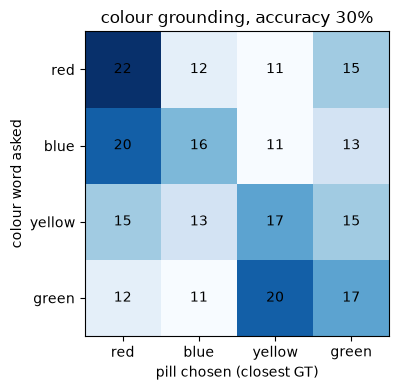

In [11]:
# Counterfactual colour test on all layouts -> 4x4 confusion matrix (word asked x pill chosen) + accuracy per layout
# Run after the previous cell (needs policy, preprocessor, postprocessor, device, CF_REPO, COLOURS, idx_colour)
import pandas as pd

LAYOUT_STARTS = list(range(0, 48, 4))   # ep 0, 4, 8, ..., 44 -> 12 layouts
SEEDS = [0, 1, 2, 3, 4]
JOINTS = [0,1,2]                       # pan, shoulder lift, elbow. [0] = pan only (can't tell centre from back)
T_END = 35                               # last step of the 50-step chunk

confusion = np.zeros((4, 4), dtype=int)
layout_acc = {}
for L in LAYOUT_STARTS:
    # Ground truth: end-of-chunk joints of each episode in the layout, keyed by its colour word
    gt_end = {}
    compartments = set()
    for ep in range(L, L + 4):
        ds_ep = LeRobotDataset(CF_REPO, episodes = [ep], download_videos = True)
        task_ep = ds_ep[idx_colour]["task"]
        colour_ep = next(c for c in COLOURS if f" {c} " in task_ep)
        gt_end[colour_ep] = np.stack(ds_ep.hf_dataset['action'])[idx_colour + T_END, JOINTS]
        compartments.add(task_ep.split(" in the ")[1])
        if ep == L:
            ds_obs, task_ref, colour_ref = ds_ep, task_ep, colour_ep
    assert len(gt_end) == 4 and len(compartments) == 1, f"layout at ep {L} is not 4 colours / 1 compartment"

    gt_sep = min(np.linalg.norm(gt_end[a] - gt_end[b]) for a in COLOURS for b in COLOURS if a < b)
    print(f"layout ep {L:2d}: {task_ref.split(' in the ')[1]:22s} min GT separation = {gt_sep:.1f}")

    # Same observation (frame idx_colour of the layout's first episode) for all 4 words
    input_features["observation.state"] = ds_obs[idx_colour]["observation.state"].unsqueeze(0)
    input_features["observation.images.front"] = ds_obs[idx_colour]["observation.images.front"].unsqueeze(0)

    n_correct = 0
    for a, colour in enumerate(COLOURS):
        obs_prompt = {
            "observation.state": input_features["observation.state"],
            "observation.images.front": input_features["observation.images.front"],
            "task": task_ref.replace(f" {colour_ref} ", f" {colour} "),
        }
        batch_prompt = preprocessor(obs_prompt)
        batch_prompt = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch_prompt.items()}

        for s in SEEDS:
            gen = torch.Generator(device=device).manual_seed(s)
            noise = torch.randn(1, policy.config.chunk_size, policy.config.max_action_dim,
                                generator=gen, device=device)
            policy.reset()
            act = postprocessor(policy.predict_action_chunk(batch_prompt, noise=noise.clone())).squeeze(0).numpy()
            pred_end = act[T_END, JOINTS]
            chosen = min(COLOURS, key=lambda c: np.linalg.norm(pred_end - gt_end[c]))
            confusion[a, COLOURS.index(chosen)] += 1
            n_correct += (chosen == colour)

    layout_acc[L // 4] = n_correct / (4 * len(SEEDS))
    print(f"layout {L // 4:2d} (ep {L}-{L + 3}): accuracy = {layout_acc[L // 4]:.0%}")

# Summary
print(pd.DataFrame(confusion, index=[f"asked {c}" for c in COLOURS], columns=[f"chose {c}" for c in COLOURS]))
acc = np.trace(confusion) / confusion.sum()
print(f"accuracy = {acc:.1%}  (chance = 25%, n = {confusion.sum()})")

# EXPECTED_CORRECT = 81   # checkpoint 3000, SEEDS 0-4, idx_colour = 10, T_END = 49, JOINTS = [0, 1, 2]
# n_total_correct = int(np.trace(confusion))
# print(f"reproducibility: {n_total_correct}/{confusion.sum()} (expected {EXPECTED_CORRECT}/240)")
# if n_total_correct != EXPECTED_CORRECT:
#     print("WARNING: total changed, so something in the setup is different")

# acc_visible = np.mean([layout_acc[k] for k in range(0, 8)])
# acc_hidden  = np.mean([layout_acc[k] for k in range(8, 12)])
# print(f"layouts 0-7: {acc_visible:.0%}   layouts 8-11: {acc_hidden:.0%}   (chance = 25%)")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(4), COLOURS); ax.set_yticks(range(4), COLOURS)
ax.set_xlabel("pill chosen (closest GT)"); ax.set_ylabel("colour word asked")
for i in range(4):
    for j in range(4):
        ax.text(j, i, confusion[i, j], ha="center", va="center")
ax.set_title(f"colour grounding, accuracy {acc:.0%}")
plt.tight_layout()
fig.savefig("cf_colour_confusion.png", dpi=150)

In [103]:
import re
import numpy as np
import pandas as pd
from lerobot.datasets.lerobot_dataset import LeRobotDataset

SOURCES = {
    "v3":     "TomasAnderegg/so101_pill_sorting_v3",
    "DAgger": "TomasAnderegg/rollout_pill_sorting_dagger_v3",
}
GRIPPER, PAN, LIFT = 5, 0, 1

REST_MAX = 4.5   # gripper below this = closed on nothing (rest ≈ 2); holding a pill ≈ 7–8 or ≈ 17

def grasp_frame(g, drop=3.0, win=10, smooth=5, hold=15):
    """Grasp = the largest sudden closing that ends on a holding plateau (above rest)."""
    gs = np.convolve(np.pad(g, smooth // 2, mode="edge"), np.ones(smooth) / smooth, mode="valid")
    d = np.zeros_like(gs)
    d[:-win] = gs[win:] - gs[:-win]                      # change over the next `win` frames
    closing = d < -drop
    starts = np.flatnonzero(closing & ~np.r_[False, closing[:-1]])

    best, best_drop = None, 0.0
    for k in starts:
        end = min(k + win, len(gs) - 1)
        plateau = np.median(gs[end:end + hold])           # level the gripper settles at
        size = d[k:k + win].min()                         # how big the closing is
        if plateau > REST_MAX and size < best_drop:       # closed on a pill, and biggest so far
            best, best_drop = int(k + win // 2), size
    return best

rows, curves = [], {}
for part, repo in SOURCES.items():
    ds = LeRobotDataset(repo, download_videos=False)
    data = ds.hf_dataset.with_format("numpy")
    ep_idx = np.asarray(data["episode_index"])
    state = np.stack(data["observation.state"])

    eps = ds.meta.episodes
    eps = eps.to_pandas() if hasattr(eps, "to_pandas") else pd.DataFrame(eps)
    task_of = dict(zip(eps["episode_index"], eps["tasks"].apply(lambda t: t[0])))

    for ep in np.unique(ep_idx):
        s = state[ep_idx == ep]
        k = grasp_frame(s[:, GRIPPER])
        task = task_of[int(ep)]
        m = re.search(r"the (\w+) pill", task)
        curves[(part, int(ep))] = (s[:, GRIPPER], k)
        rows.append({
            "part": part, "episode": int(ep), "task": task,
            "colour": m.group(1) if m else "?",
            "grasp_frame": k,
            "pan":  s[k, PAN]  if k is not None else np.nan,
            "lift": s[k, LIFT] if k is not None else np.nan,
        })

df = pd.DataFrame(rows)
print(df.groupby("part")["pan"].apply(lambda x: f"{x.notna().sum()}/{len(x)} episodes with a grasp"))

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

part
DAgger      60/60 episodes with a grasp
v3        300/300 episodes with a grasp
Name: pan, dtype: object


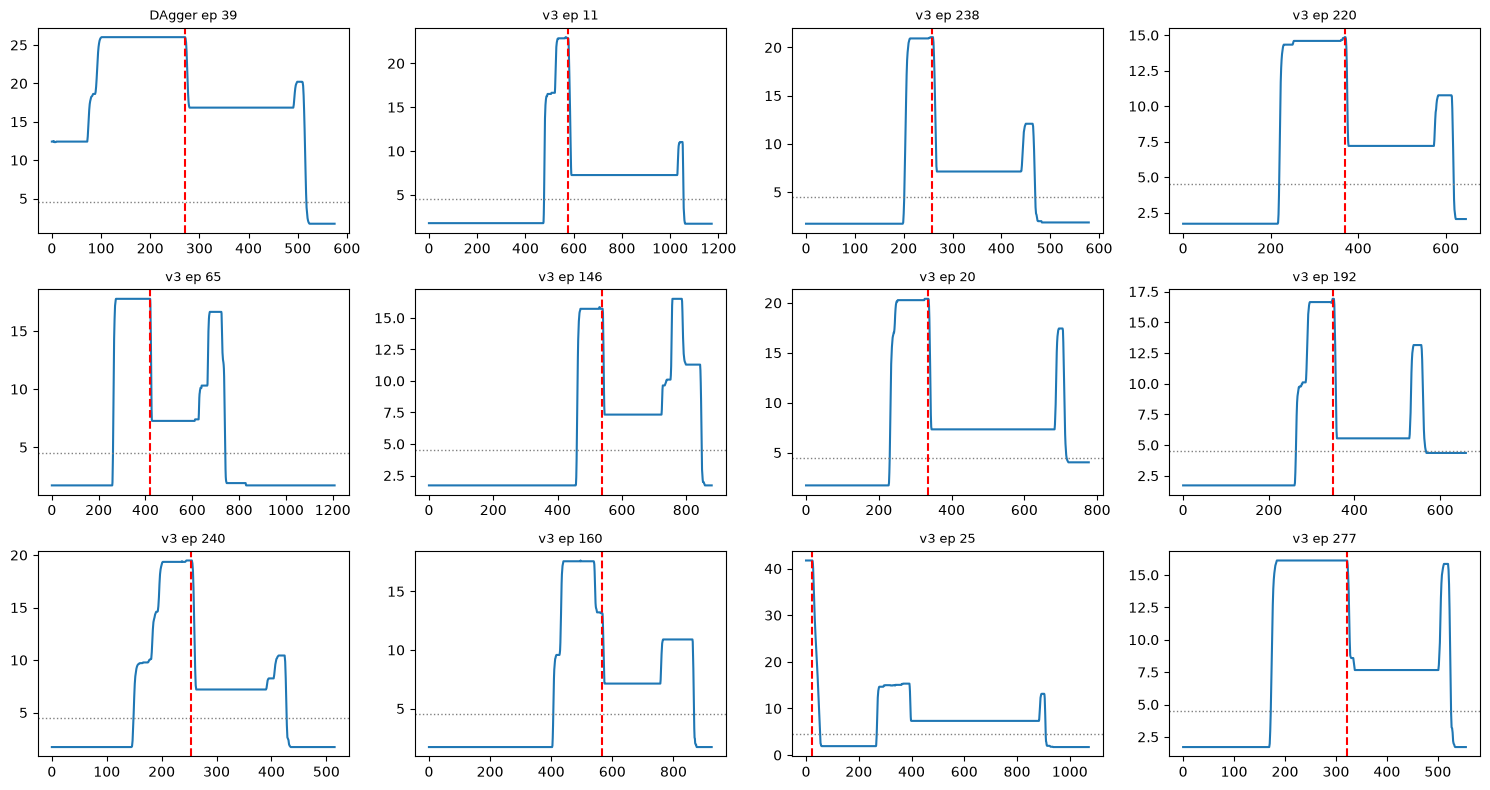

In [104]:
check = [("DAgger", 39), ("v3", 11), ("v3", 238)] + \
        list(df.sample(9, random_state=2)[["part", "episode"]].itertuples(index=False, name=None))

fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, (part, ep) in zip(axes.flat, check):
    g, _ = curves[(part, ep)]
    k = grasp_frame(g)
    ax.plot(g)
    ax.axhline(REST_MAX, color="gray", ls=":", lw=1)
    if k is not None:
        ax.axvline(k, color="red", ls="--")
    ax.set_title(f"{part} ep {ep}", fontsize=9)
plt.tight_layout(); plt.show()

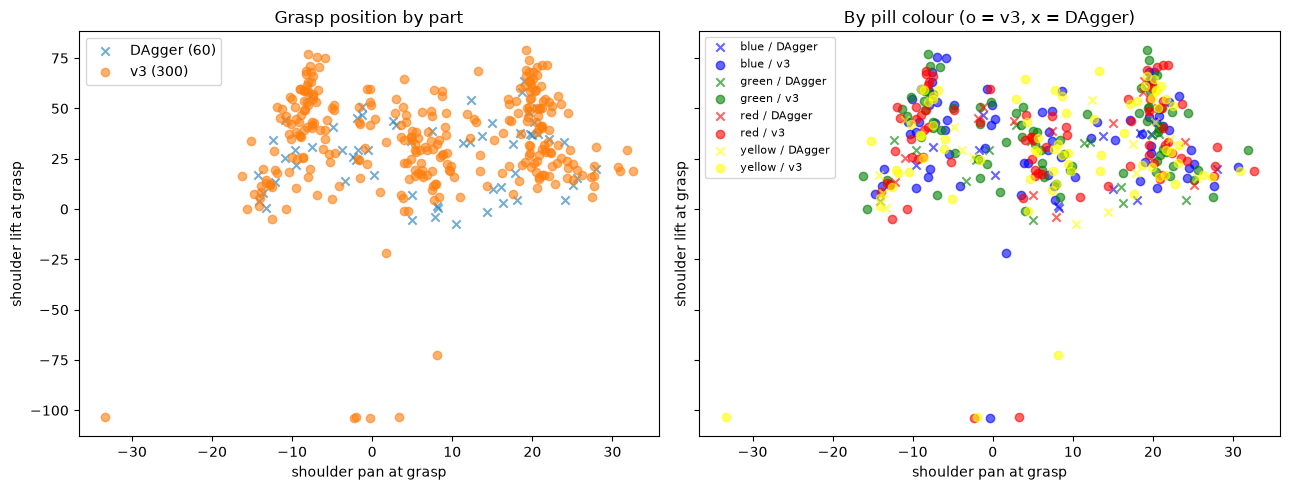

count  mean   std
part   colour                   
DAgger blue       15   5.8  12.8
       green      15   7.0  11.3
       red        15   9.2  12.2
       yellow     15   5.1  14.6
v3     blue       75   6.1  12.9
       green      75   6.7  12.8
       red        75   6.7  13.8
       yellow     75   6.9  13.5

In [105]:
import matplotlib.colors as mcolors

pts = df.dropna(subset=["pan"])
mk = {"v3": "o", "DAgger": "x"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for part, g in pts.groupby("part"):
    a1.scatter(g["pan"], g["lift"], marker=mk[part], alpha=0.6, label=f"{part} ({len(g)})")
a1.set_title("Grasp position by part")
a1.legend()

for (colour, part), g in pts.groupby(["colour", "part"]):
    c = colour if mcolors.is_color_like(colour) else "gray"
    a2.scatter(g["pan"], g["lift"], color=c, marker=mk[part], alpha=0.6, label=f"{colour} / {part}")
a2.set_title("By pill colour (o = v3, x = DAgger)")
a2.legend(fontsize=8)

for a in (a1, a2):
    a.set_xlabel("shoulder pan at grasp")
    a.set_ylabel("shoulder lift at grasp")
plt.tight_layout(); plt.show()

display(pts.groupby(["part", "colour"])["pan"].agg(["count", "mean", "std"]).round(1))

In [106]:
pans = []
for seed in range(20):
    g = torch.Generator(device=device).manual_seed(seed)
    nz = torch.randn(1, policy.config.chunk_size, policy.config.max_action_dim, generator=g, device=device)
    policy.reset()
    a = postprocessor(policy.predict_action_chunk(batch, noise=nz)).squeeze(0).numpy()
    pans.append(a[-10:, 0].mean())          # where the shoulder pan is heading at the end of the chunk

plt.hist(pans, bins=15)
plt.xlabel("shoulder pan at end of chunk")
plt.ylabel("number of seeds")
plt.show()

NameError: name 'batch' is not defined

In [ ]:
import os
os.environ["HF_HUB_CACHE"] = r"D:\SmolVLA_chkpt\.hf_cache"     # keep the HF cache off C:

import shutil
from huggingface_hub import HfApi, snapshot_download

REPO = "TomasAnderegg/pill_sorting_full_ft_a100_v3_dagger60"
DEST = r"D:\SmolVLA_chkpt\big_data_v3_dagger_60"

# 1. How much will it take, and is there room?
files = [f for f in HfApi().list_repo_tree(REPO, recursive=True)
         if getattr(f, "size", None) and f.path.startswith("checkpoints/") and "/pretrained_model/" in f.path]
need = sum(f.size for f in files) / 1e9
free = shutil.disk_usage("D:\\").free / 1e9
print(f"{len(files)} files, {need:.1f} GB to download, {free:.1f} GB free on D:")

# 2. Download (only pretrained_model, no training_state)
if need < free * 0.9:
    snapshot_download(REPO, local_dir=DEST, allow_patterns=["checkpoints/*/pretrained_model/*"])
    print("done →", DEST)
else:
    print("Not enough space on D:, free some space or download fewer checkpoints")

In [ ]:
# import cv2
# import numpy as np
# import torch
# import matplotlib.pyplot as plt

# img = (observation_image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)   # H, W, 3 (RGB)
# hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
# print("valeurs hsv:", hsv)                                 # H in 0..180, S/V in 0..255
# H, S, V = hsv[..., 0].astype(int), hsv[..., 1].astype(int), hsv[..., 2].astype(int)

# # Colour masks: tune the numbers if a mask misses part of a pill or picks up the background
# masks = {
#     "red":  ((H < 8) | (H > 170)) & (S > 120) & (V > 80),
#     "blue": (H > 95) & (H < 115) & (S > 120) & (V > 80),
# }

# def circ_mean_h(h):
#     """Mean of OpenCV hues (0..180), handling the wrap-around at red."""
#     a = np.deg2rad(h.astype(float) * 2)
#     return (np.rad2deg(np.arctan2(np.sin(a).mean(), np.cos(a).mean())) / 2) % 180

# def swap_pill_colours(hsv, m_a, m_b):
#     out = hsv.copy()
#     for src, dst in [(m_a, m_b), (m_b, m_a)]:
#         out[..., 0][src] = circ_mean_h(hsv[..., 0][dst])          # take the other pill's hue
#         out[..., 1][src] = np.median(hsv[..., 1][dst])            # and its saturation
#     return out                                                    # brightness (V) unchanged

# swapped_rgb = cv2.cvtColor(swap_pill_colours(hsv, masks["red"], masks["blue"]), cv2.COLOR_HSV2RGB)
# image_swap = torch.from_numpy(swapped_rgb).permute(2, 0, 1).float() / 255     # back to [3, H, W] in [0, 1]

# fig, axes = plt.subplots(1, 4, figsize=(18, 4))
# axes[0].imshow(img);                  axes[0].set_title("original")
# axes[1].imshow(masks["red"]);         axes[1].set_title("red mask")
# axes[2].imshow(masks["blue"]);        axes[2].set_title("blue mask")
# axes[3].imshow(swapped_rgb);          axes[3].set_title("red ↔ blue swapped")
# for ax in axes:
#     ax.axis("off")
# plt.tight_layout()
# plt.show()

### Data augmentation: Colour swap part

In [43]:
import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
from lerobot.datasets.lerobot_dataset import LeRobotDataset

REPO = "TomasAnderegg/pill_sorting_colour_direct_mix_v1"
OUT = r"C:\Users\tjga9\Documents\Tomas\Projets\LeRobot\swap_episode0.mp4"
ds = LeRobotDataset(REPO, download_videos = True)
swap_colour_ds = LeRobotDataset.create("TomasAnderegg/pill_sorting_colour_direct_mix_v1_swap", fps=ds.meta.fps, features=ds.meta.features,
                            robot_type=ds.meta.robot_type)
writer = None 
for ep in range(ds.num_episodes):
    start = ds.meta.episodes["dataset_from_index"][ep]
    end = ds.meta.episodes["dataset_to_index"][ep]
     

    #Task swap
    task_swap = ds[start]["task"].replace("red", "X").replace("blue", "red").replace("X", "blue")

    for i in range(start,end):
    
        frame = ds[i]
        ## Open CV expect: a Numpy array,  (height, width, channels), uint8, values 0–255.
        # print(ds[450]["observation.images.front"])

        img = (frame["observation.images.front"].permute(1,2,0).numpy()*255).astype(np.uint8)
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

        # fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        # ax1.imshow(img); ax1.set_title("RGB"); 
        # ax2.imshow(hsv); ax2.set_title("HSV"); 
        # plt.tight_layout()
        # plt.show()

        # print(hsv[150, 200]) #red pill HSV value
        # RED_H = 3
        # BLUE_H = 104
        # print(hsv[200,500]) #blue pill HSV value 
        h = hsv[...,0]
        s = hsv[...,1]
        v = hsv[...,2]
        red_mask = ((h < 13) | (h > 170)) &  (s > 90) & (v > 60)
        # plt.imshow(red_mask)
        blue_mask = (h > 95) & (h < 115) & (s > 90) & (v > 60)
        
        close_kernel = np.ones((7, 7), np.uint8)
        red_mask = cv2.morphologyEx(red_mask.astype(np.uint8), cv2.MORPH_CLOSE, close_kernel)
        blue_mask = cv2.morphologyEx(blue_mask.astype(np.uint8), cv2.MORPH_CLOSE, close_kernel)


        swap_hsv = hsv.copy()

        kernel = np.ones((5, 5), np.uint8)

        # bool → uint8 for OpenCV, then back to bool for masking
        red_mask_dil  = cv2.dilate(red_mask.astype(np.uint8),  kernel, iterations=1).astype(bool)
        blue_mask_dil = cv2.dilate(blue_mask.astype(np.uint8), kernel, iterations=1).astype(bool)
        

        #Swap red
        swap_hsv[...,0][red_mask_dil] = 104
        swap_hsv[...,1][red_mask_dil] = 124 
        #Swap blue 
        swap_hsv[...,0][blue_mask_dil] = 3
        swap_hsv[...,1][blue_mask_dil] = 144

        rgb_img = cv2.cvtColor(swap_hsv, cv2.COLOR_HSV2RGB)
        
        swap_colour_ds.add_frame({
            "observation.images.front": rgb_img,
            "observation.state": frame["observation.state"].numpy(),
            "action": frame["action"].numpy(),
            "task": task_swap,
        })
    swap_colour_ds.save_episode()
swap_colour_ds.finalize()

    ##Visualize the result:
    # frame = np.hstack([img, rgb_img])                    # original | swapped, side by side
    # if writer is None:
    #     H, W = frame.shape[:2]
    #     writer = cv2.VideoWriter(OUT, cv2.VideoWriter_fourcc(*"mp4v"), ds.meta.fps, (W, H))
    # writer.write(cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))  # OpenCV writes BGR

# writer.release()
# print("saved", OUT)

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
# ax1.imshow(img); ax1.set_title("RGB"); 
# ax2.imshow(rgb_img); ax2.set_title("swap RGB"); 
# plt.tight_layout()
# plt.show()

# fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5))
# ax1.imshow(img); ax1.set_title("RGB"); 
# ax2.imshow(red_mask); ax2.set_title("red mask");
# ax3.imshow(blue_mask); ax3.set_title("blue mask"); 
# plt.tight_layout()
# plt.show()

# print(ds[450]["observation.images.front"].numpy())

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

Fetching 4 files: 100%|██████████| 4/4 [00:00<?, ?it/s]
          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call l

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

68 episodes, 36953 frames
episode 0 : Put the red pill in the circle compartment.
episode 1 : Put the yellow pill in the cross compartment.
episode 2 : Put the green pill in the circle compartment.
episode 3 : Put the blue pill in the circle compartment.
episode 4 : Put the blue pill in the cross compartment.
episode 5 : Put the red pill in the triangle compartment.
episode 6 : Put the blue pill in the triangle compartment.
episode 7 : Put the yellow pill in the square compartment.
episode 8 : Put the green pill in the circle compartment.
episode 9 : Put the green pill in the cross compartment.
episode 10 : Put the red pill in the triangle compartment.
episode 11 : Put the green pill in the cross compartment.
episode 12 : Put the yellow pill in the triangle compartment.
episode 13 : Put the red pill in the square compartment.
episode 14 : Put the yellow pill in the cross compartment.
episode 15 : Put the red pill in the circle compartment.
episode 16 : Put the red pill in the square co

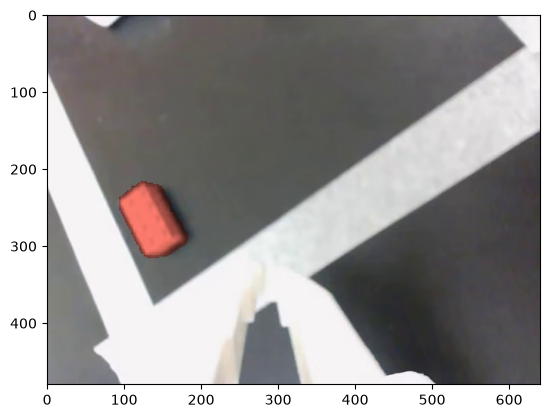

In [44]:
ds_swap = LeRobotDataset("TomasAnderegg/pill_sorting_colour_direct_mix_v1_swap")
print(ds_swap.meta.total_episodes, "episodes,", ds_swap.meta.total_frames, "frames")   # expected: 2 episodes, 1828 frames

for ep in range(ds_swap.num_episodes):
    start = ds_swap.meta.episodes["dataset_from_index"][ep]
    print("episode", ep, ":", ds_swap[start]["task"])

plt.imshow(ds_swap[0]["observation.images.front"].permute(1,2,0))

In [45]:
ds_swap.push_to_hub()

### Swap all colours cf_dataset

In [74]:
# A. Swap functions: the logic of cell 42, unchanged, wrapped in functions
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
from collections import Counter
from tqdm import tqdm
from lerobot.datasets.lerobot_dataset import LeRobotDataset

CF_SRC  = "TomasAnderegg/so101_pill_sorting_colour_cf_v2"
CF_SWAP = "TomasAnderegg/so101_pill_sorting_colour_cf_v2_swap"
CAM = "observation.images.front"

def swap_task(task):
    # same placeholder trick as cell 42: red -> X -> blue, blue -> red
    return task.replace("red", "X").replace("blue", "red").replace("X", "blue")

def to_uint8(img_tensor):
    # Open CV expects (height, width, channels), uint8, values 0-255 (as in cell 42)
    return (img_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

def swap_red_blue(img):
    """img: H x W x 3 uint8 RGB -> red/blue swapped RGB (cell 42 logic)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h = hsv[..., 0]
    s = hsv[..., 1]
    v = hsv[..., 2]
    red_mask = ((h < 13) | (h > 170)) & (s > 90) & (v > 60)
    blue_mask = (h > 95) & (h < 115) & (s > 90) & (v > 60)

    close_kernel = np.ones((7, 7), np.uint8)
    red_mask = cv2.morphologyEx(red_mask.astype(np.uint8), cv2.MORPH_CLOSE, close_kernel)
    blue_mask = cv2.morphologyEx(blue_mask.astype(np.uint8), cv2.MORPH_CLOSE, close_kernel)

    swap_hsv = hsv.copy()

    kernel = np.ones((5, 5), np.uint8)
    # bool -> uint8 for OpenCV, then back to bool for masking
    red_mask_dil = cv2.dilate(red_mask.astype(np.uint8), kernel, iterations=1).astype(bool)
    blue_mask_dil = cv2.dilate(blue_mask.astype(np.uint8), kernel, iterations=1).astype(bool)

    # Swap red
    swap_hsv[..., 0][red_mask_dil] = 104
    swap_hsv[..., 1][red_mask_dil] = 124
    # Swap blue
    swap_hsv[..., 0][blue_mask_dil] = 3
    swap_hsv[..., 1][blue_mask_dil] = 144

    return cv2.cvtColor(swap_hsv, cv2.COLOR_HSV2RGB)

def ep_bounds(meta, ep):
    return meta.episodes["dataset_from_index"][ep], meta.episodes["dataset_to_index"][ep]

def frame0(ds, ep):
    start, _ = ep_bounds(ds.meta, ep)
    return ds[start]

print("swap functions ready")

swap functions ready


          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

48 episodes, 16433 frames
episode 0: 'Put the yellow pill in the circle compartment.'     -> 'Put the yellow pill in the circle compartment.'
episode 1: 'Put the blue pill in the circle compartment.'       -> 'Put the red pill in the circle compartment.'
episode 2: 'Put the red pill in the circle compartment.'        -> 'Put the blue pill in the circle compartment.'
episode 3: 'Put the green pill in the circle compartment.'      -> 'Put the green pill in the circle compartment.'


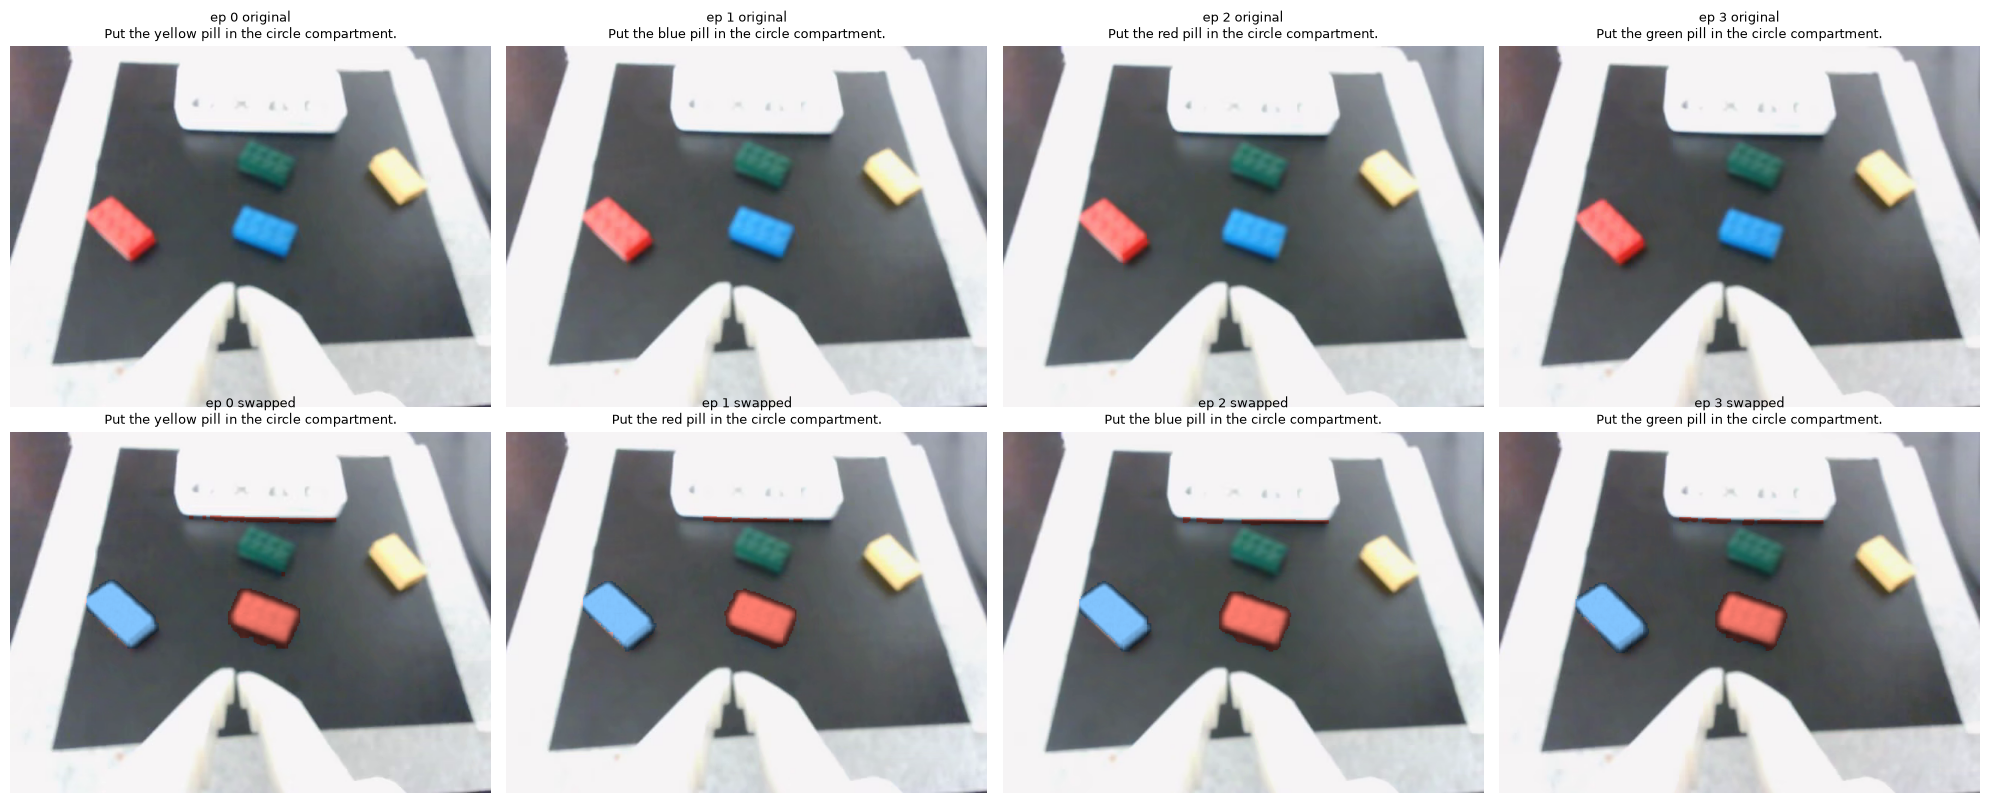

In [75]:
# B. TEST on episodes 0-3 (first layout) only: nothing is written. Check the grid before running C.
ds_cf = LeRobotDataset(CF_SRC, download_videos=True)
print(ds_cf.meta.total_episodes, "episodes,", ds_cf.meta.total_frames, "frames")   # expected: 48 episodes, 16433 frames

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ep in range(4):
    f = frame0(ds_cf, ep)
    img = to_uint8(f[CAM])
    axes[0, ep].imshow(img)
    axes[0, ep].set_title(f"ep {ep} original\n{f['task']}", fontsize=9)
    axes[1, ep].imshow(swap_red_blue(img))
    axes[1, ep].set_title(f"ep {ep} swapped\n{swap_task(f['task'])}", fontsize=9)
    print(f"episode {ep}: {f['task']!r:52} -> {swap_task(f['task'])!r}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [76]:
# C. FULL RUN: every episode, every frame (only after B looks right). Same pattern as cell 42.
from lerobot.utils.constants import HF_LEROBOT_HOME

ds_cf = LeRobotDataset(CF_SRC, download_videos=True)
swap_root = HF_LEROBOT_HOME / CF_SWAP
assert not swap_root.exists(), f"{swap_root} already exists: delete it (or rename it) before running again"

swap_cf_ds = LeRobotDataset.create(CF_SWAP, fps=ds_cf.meta.fps, features=ds_cf.meta.features,
                                   robot_type=ds_cf.meta.robot_type)
for ep in tqdm(range(ds_cf.num_episodes), desc="episodes"):
    start, end = ep_bounds(ds_cf.meta, ep)
    task_swap = swap_task(ds_cf[start]["task"])          # only red/blue words change
    for i in range(start, end):
        frame = ds_cf[i]
        swap_cf_ds.add_frame({
            CAM: swap_red_blue(to_uint8(frame[CAM])),        # image swapped in EVERY episode
            "observation.state": frame["observation.state"].numpy(),
            "action": frame["action"].numpy(),
            "task": task_swap,
        })
    swap_cf_ds.save_episode()
swap_cf_ds.finalize()
print("written to", swap_root)

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

written to C:\Users\tjga9\.cache\huggingface\lerobot\TomasAnderegg\so101_pill_sorting_colour_cf_v2_swap


          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

source : 48 episodes, 16433 frames
swapped: 48 episodes, 16433 frames
per-episode lengths identical: True 
tasks mapped as expected: True; 16 distinct tasks, counts [3]

layout  episodes   max mean-abs diff (0-255)   original   swapped
     0   0-3                                  6.19      6.23
     1   4-7                                 13.01     12.91
     2   8-11                                 5.34      5.42
     3  12-15                                 9.85      9.86
     4  16-19                                 5.09      5.22
     5  20-23                                 4.51      4.61
     6  24-27                                 8.43      8.44
     7  28-31                                 6.00      6.08
     8  32-35                                 7.30      7.44
     9  36-39                                12.61     12.41
    10  40-43                                 7.57      7.61
    11  44-47                                 3.14      3.28


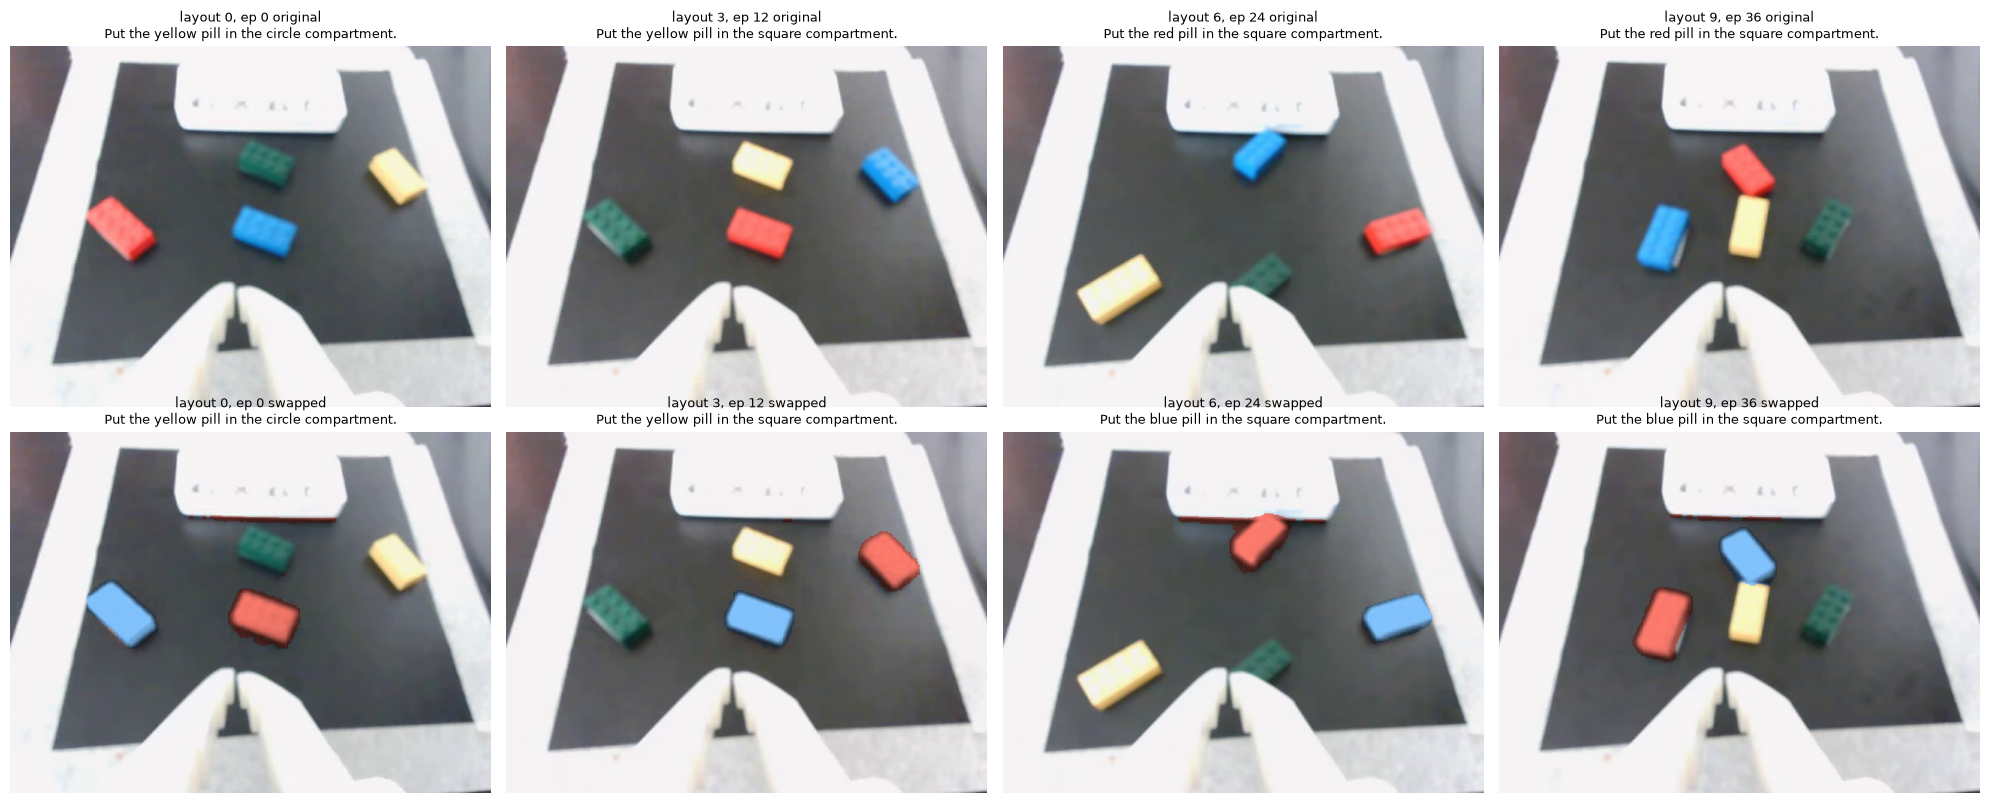


ALL_OK = True


In [77]:
# D. CHECKS on the swapped dataset (loaded fresh from disk). Don't push unless ALL_OK is True.
src = LeRobotDataset(CF_SRC, download_videos=True)
swp = LeRobotDataset(CF_SWAP, download_videos=True)
problems = []

# 1. Episodes, frames, per-episode lengths
print(f"source : {src.meta.total_episodes} episodes, {src.meta.total_frames} frames")
print(f"swapped: {swp.meta.total_episodes} episodes, {swp.meta.total_frames} frames")
if (swp.meta.total_episodes, swp.meta.total_frames) != (48, 16433):
    problems.append("expected 48 episodes and 15130 frames")
if (swp.meta.fps, swp.meta.robot_type) != (src.meta.fps, src.meta.robot_type):
    problems.append("fps or robot_type differ from the source")
if set(swp.meta.features) != set(src.meta.features):
    problems.append(f"features differ: {set(swp.meta.features) ^ set(src.meta.features)}")
len_src = [b - a for a, b in (ep_bounds(src.meta, e) for e in range(src.num_episodes))]
len_swp = [b - a for a, b in (ep_bounds(swp.meta, e) for e in range(swp.num_episodes))]
bad_len = [e for e, (a, b) in enumerate(zip(len_src, len_swp)) if a != b]
print("per-episode lengths identical:", len_src == len_swp, "" if not bad_len else f"(differ: {bad_len})")
if len_src != len_swp:
    problems.append(f"episode lengths differ: {bad_len}")

# 2. Tasks: source -> expected swap (red<->blue, yellow/green unchanged); each task 3 times
t_src = [frame0(src, e)["task"] for e in range(src.num_episodes)]
t_swp = [frame0(swp, e)["task"] for e in range(swp.num_episodes)]
bad_task = [(e, a, b) for e, (a, b) in enumerate(zip(t_src, t_swp)) if swap_task(a) != b]
for e, a, b in bad_task:
    print(f"  episode {e}: {a!r} -> {b!r}, expected {swap_task(a)!r}")
for a, b in zip(t_src, t_swp):
    if ("yellow" in a or "green" in a) and a != b:
        bad_task.append(("yellow/green changed", a, b))
counts = Counter(t_swp)
print(f"tasks mapped as expected: {not bad_task}; {len(counts)} distinct tasks, counts {sorted(set(counts.values()))}")
if bad_task:
    problems.append(f"{len(bad_task)} task(s) not swapped as expected")
if len(counts) != 16 or set(counts.values()) != {3}:
    problems.append(f"expected 16 tasks x 3 episodes, got {dict(counts)}")

# 3. Frame 0 inside each layout (episodes 4k..4k+3): max mean-abs pixel difference between its 4 episodes
def layout_spread(ds, k):
    imgs = [to_uint8(frame0(ds, e)[CAM]).astype(np.float32) for e in range(4 * k, 4 * k + 4)]
    return max(np.abs(imgs[a] - imgs[b]).mean() for a in range(4) for b in range(a + 1, 4))

print("\nlayout  episodes   max mean-abs diff (0-255)   original   swapped")
for k in range(src.num_episodes // 4):
    o, s = layout_spread(src, k), layout_spread(swp, k)
    flag = "  <-- much larger than the original" if s > 1.5 * o + 1.0 else ""
    print(f"{k:>6}  {4*k:>2}-{4*k+3:<2}{'':29}{o:>8.2f}{s:>10.2f}{flag}")
    if flag:
        problems.append(f"layout {k}: frame-0 spread {s:.2f} vs {o:.2f} in the original")

# 4. Frame 0, original vs swapped, for layouts 0, 3, 6, 9 (first episode of each layout)
show = [k for k in (0, 3, 6, 9) if 4 * k < swp.num_episodes]
fig, axes = plt.subplots(2, 4, figsize=(20, 8), squeeze=False)
for col, k in enumerate(show):
    e = 4 * k
    axes[0, col].imshow(to_uint8(frame0(src, e)[CAM])); axes[0, col].set_title(f"layout {k}, ep {e} original\n{t_src[e]}", fontsize=9)
    axes[1, col].imshow(to_uint8(frame0(swp, e)[CAM])); axes[1, col].set_title(f"layout {k}, ep {e} swapped\n{t_swp[e]}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

ALL_OK = not problems
print("\nALL_OK =", ALL_OK)
for p in problems:
    print("  -", p)

In [78]:
# E. PUSH (only after D printed ALL_OK = True and the images look right)
assert ALL_OK, "checks in D failed: not pushing"
ds_cf_swap = LeRobotDataset(CF_SWAP)
print(ds_cf_swap.meta.total_episodes, "episodes,", ds_cf_swap.meta.total_frames, "frames")
ds_cf_swap.push_to_hub()

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

48 episodes, 16433 frames


## Data oversampled

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

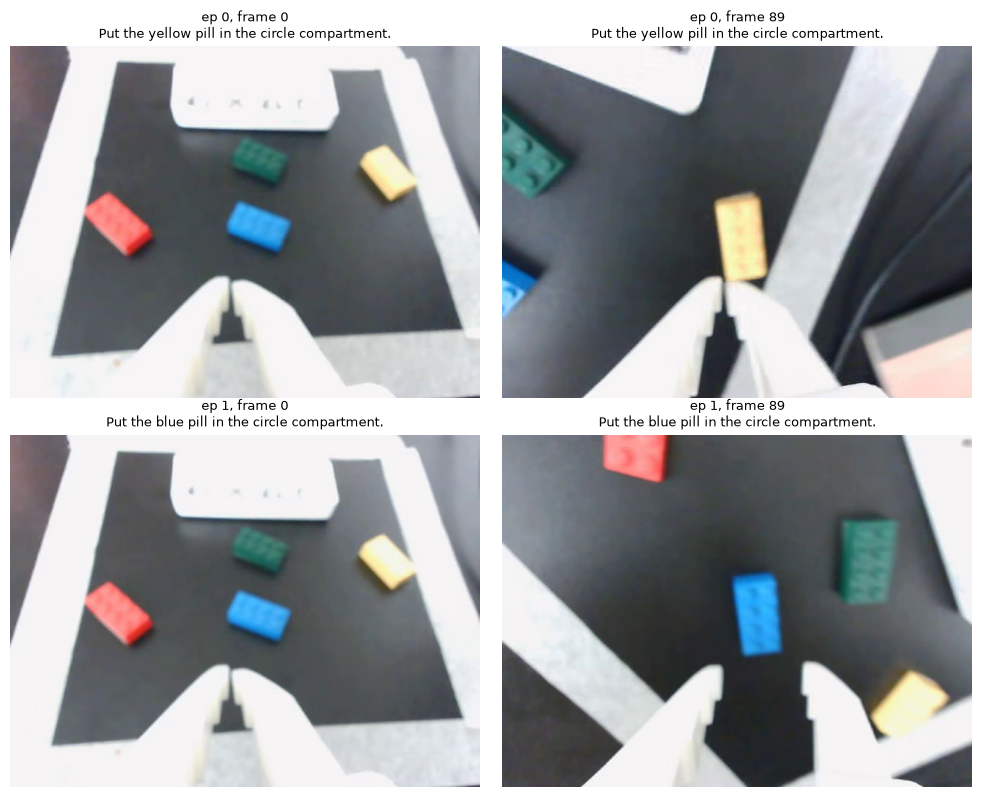

In [88]:
# Departure dataset: TEST on 2 episodes (nothing written)
import numpy as np
import torch
import matplotlib.pyplot as plt
from lerobot.datasets.lerobot_dataset import LeRobotDataset

DEP_SOURCES = ["TomasAnderegg/so101_pill_sorting_colour_cf_v2", "TomasAnderegg/so101_pill_sorting_colour_cf_v2_swap"]
DEP = "TomasAnderegg/so101_pill_sorting_colour_cf_v2_departure_x3"
N_FRAMES, N_COPIES = 90, 3
CAM = "observation.images.front"

ds = LeRobotDataset(DEP_SOURCES[0], download_videos=True)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, ep in enumerate([0, 1]):
    start = ds.meta.episodes["dataset_from_index"][ep]
    for col, i in enumerate([0, N_FRAMES - 1]):
        f = ds[start + i]
        axes[row, col].imshow(f[CAM].permute(1, 2, 0))
        axes[row, col].set_title(f"ep {ep}, frame {i}\n{f['task']}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [89]:
# Departure dataset: FULL BUILD (first 90 frames of every episode, written 3 times)
from tqdm import tqdm
from lerobot.utils.constants import HF_LEROBOT_HOME

assert not (HF_LEROBOT_HOME / DEP).exists(), f"{HF_LEROBOT_HOME / DEP} already exists: delete it before building again"
src0 = LeRobotDataset(DEP_SOURCES[0], download_videos=True)
dep_ds = LeRobotDataset.create(DEP, fps=src0.meta.fps, features=src0.meta.features, robot_type=src0.meta.robot_type)

for repo in DEP_SOURCES:
    ds = LeRobotDataset(repo, download_videos=True)
    for ep in tqdm(range(ds.num_episodes), desc=repo.split("/")[1]):
        start = ds.meta.episodes["dataset_from_index"][ep]
        end = ds.meta.episodes["dataset_to_index"][ep]
        assert end - start >= N_FRAMES, f"{repo} episode {ep} has only {end - start} frames"
        frames = [ds[start + i] for i in range(N_FRAMES)]        # decode once, write 3 times
        for copy in range(N_COPIES):
            for f in frames:
                dep_ds.add_frame({
                    CAM: (f[CAM].permute(1, 2, 0).numpy() * 255).astype(np.uint8),
                    "observation.state": f["observation.state"].numpy(),
                    "action": f["action"].numpy(),
                    "task": f["task"],
                })
            dep_ds.save_episode()
dep_ds.finalize()

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

In [90]:
# Departure dataset: CHECKS (don't push unless DEP_OK is True)
from collections import Counter

dep = LeRobotDataset(DEP)
srcs = [LeRobotDataset(r) for r in DEP_SOURCES]
problems = []

# Totals and lengths
lengths = [b - a for a, b in zip(dep.meta.episodes["dataset_from_index"], dep.meta.episodes["dataset_to_index"])]
print(dep.meta.total_episodes, "episodes,", dep.meta.total_frames, "frames")   # expected: 288 episodes, 25920 frames
if (dep.meta.total_episodes, dep.meta.total_frames) != (288, 25920):
    problems.append("expected 288 episodes and 25920 frames")
if set(lengths) != {N_FRAMES}:
    problems.append(f"episode lengths not all {N_FRAMES}: {sorted(set(lengths))}")

# A few episodes: state, action and task identical to the source frames 0..89, in all 3 copies
def rows(ds, ep):
    start = ds.meta.episodes["dataset_from_index"][ep]
    r = ds.hf_dataset[start:start + N_FRAMES]
    return torch.stack(r["observation.state"]), torch.stack(r["action"])

for s, ep in [(0, 0), (0, srcs[0].num_episodes - 1), (1, 0), (1, srcs[1].num_episodes - 1)]:
    st_src, ac_src = rows(srcs[s], ep)
    for copy in range(N_COPIES):
        d = (s * srcs[0].num_episodes + ep) * N_COPIES + copy      # build order: source, episode, copy
        st_dep, ac_dep = rows(dep, d)
        same = (torch.equal(st_src, st_dep) and torch.equal(ac_src, ac_dep)
                and dep.meta.episodes["tasks"][d] == srcs[s].meta.episodes["tasks"][ep])
        print(f"source {s} episode {ep:>2} copy {copy} -> departure episode {d:>3}: {'OK' if same else 'DIFFERENT'}")
        if not same:
            problems.append(f"departure episode {d} differs from source {s} episode {ep}")

# Tasks: 16 tasks, each 18 times (6 source episodes x 3 copies)
counts = Counter(t[0] for t in dep.meta.episodes["tasks"])
print(len(counts), "tasks, counts", sorted(set(counts.values())))           # expected: 16 tasks, counts [18]
if len(counts) != 16 or set(counts.values()) != {18}:
    problems.append(f"expected 16 tasks x 18 episodes, got {dict(counts)}")

DEP_OK = not problems
print("\nDEP_OK =", DEP_OK)
for p in problems:
    print("  -", p)

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

288 episodes, 25920 frames
source 0 episode  0 copy 0 -> departure episode   0: OK
source 0 episode  0 copy 1 -> departure episode   1: OK
source 0 episode  0 copy 2 -> departure episode   2: OK
source 0 episode 47 copy 0 -> departure episode 141: OK
source 0 episode 47 copy 1 -> departure episode 142: OK
source 0 episode 47 copy 2 -> departure episode 143: OK
source 1 episode  0 copy 0 -> departure episode 144: OK
source 1 episode  0 copy 1 -> departure episode 145: OK
source 1 episode  0 copy 2 -> departure episode 146: OK
source 1 episode 47 copy 0 -> departure episode 285: OK
source 1 episode 47 copy 1 -> departure episode 286: OK
source 1 episode 47 copy 2 -> departure episode 287: OK
16 tasks, counts [18]

DEP_OK = True


In [91]:
# Departure dataset: PUSH (only if DEP_OK)
assert DEP_OK, "checks failed: not pushing"
ds_dep = LeRobotDataset(DEP, root=HF_LEROBOT_HOME / DEP)
print(ds_dep.meta.total_episodes, "episodes,", ds_dep.meta.total_frames, "frames")
ds_dep.push_to_hub()

          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.10.0+cu128) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 8:
Traceback (most recent call last):
  File "c:\Users\tjga9\anaconda3\envs\lerobot_gpu\

288 episodes, 25920 frames


In [93]:
MIX = "TomasAnderegg/pill_sorting_colour_cf_departure_mix_v2"

!lerobot-edit-dataset --new_repo_id={MIX} --operation.type=merge --operation.repo_ids="['TomasAnderegg/so101_pill_sorting_v3_replay_direct', 'TomasAnderegg/so101_pill_sorting_colour_cf_v2', 'TomasAnderegg/so101_pill_sorting_colour_cf_v2_swap', 'TomasAnderegg/so101_pill_sorting_colour_cf_v2_departure_x3']"

'lerobot-edit-dataset' n'est pas reconnu en tant que commande interne
ou externe, un programme ex�cutable ou un fichier de commandes.


In [ ]:
import shutil
from huggingface_hub import hf_hub_download
from lerobot.utils.constants import HF_LEROBOT_HOME

stats = hf_hub_download("TomasAnderegg/pill_sorting_big_datav3_dagger_60", "meta/stats.json", repo_type="dataset")
shutil.copy(stats, HF_LEROBOT_HOME / MIX / "meta" / "stats.json")

In [ ]:
import json
import numpy as np
from huggingface_hub import hf_hub_download
from lerobot.datasets import LeRobotDatasetMetadata
from lerobot.utils.constants import HF_LEROBOT_HOME

SOURCES = ["TomasAnderegg/so101_pill_sorting_v3_replay_direct",
           "TomasAnderegg/so101_pill_sorting_colour_cf_v2",
           "TomasAnderegg/so101_pill_sorting_colour_cf_v2_swap",
           "TomasAnderegg/so101_pill_sorting_colour_cf_v2_departure_x3"]
problems = []

# Totals: mix vs sum of the sources (loaded fresh from the Hub)
src = [LeRobotDatasetMetadata(r, force_cache_sync=True) for r in SOURCES]
mix = LeRobotDatasetMetadata(MIX, root=HF_LEROBOT_HOME / MIX)
for r, m in zip(SOURCES, src):
    print(f"{r}: {m.total_episodes} episodes, {m.total_frames} frames")
exp = (sum(m.total_episodes for m in src), sum(m.total_frames for m in src))
print(f"mix: {mix.total_episodes} episodes, {mix.total_frames} frames (expected {exp[0]}, {exp[1]}; plan 404, 77984)")
if (mix.total_episodes, mix.total_frames) != exp:
    problems.append("mix totals differ from the sum of the sources")

# Departure share, from the sources
print(f"departure share: {100 * src[3].total_frames / mix.total_frames:.1f}%")   # expected: ~33%

# Stats: mix vs big_datav3_dagger_60, every stat
big = json.load(open(hf_hub_download("TomasAnderegg/pill_sorting_big_datav3_dagger_60", "meta/stats.json", repo_type="dataset")))
mine = json.load(open(HF_LEROBOT_HOME / MIX / "meta" / "stats.json"))
for key in big:
    for s in big[key]:
        same = key in mine and s in mine[key] and np.allclose(np.array(mine[key][s]), np.array(big[key][s]))
        print(f"{key:<28} {s:<6} {'OK' if same else 'DIFFERENT'}")
        if not same:
            problems.append(f"stats {key}.{s} differ from big_data")

MIX_OK = not problems
print("\nMIX_OK =", MIX_OK)
for p in problems:
    print("  -", p)

In [ ]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.utils.constants import HF_LEROBOT_HOME

assert MIX_OK, "checks failed: not pushing"
ds_mix = LeRobotDataset(MIX, root=HF_LEROBOT_HOME / MIX)
print(ds_mix.meta.total_episodes, "episodes,", ds_mix.meta.total_frames, "frames")
ds_mix.push_to_hub()